# Mərhələ 4: Kəşfiyyat Verilənlər Təhlili (Exploratory Data Analysis)

## Məqsədlər

Bu yekun mərhələdə siz:

1. Hərtərəfli birdəyişənli (univariate) təhlil aparacaqsınız
2. Xüsusiyyətlər arasındakı əlaqələri anlamaq üçün ikidəyişənli (bivariate) təhlil edəcəksiniz
3. Hədəf dəyişənin paylanmasını təhlil edəcəksiniz
4. Verilənlərdəki əsas qanunauyğunluqları və nəticələri müəyyən edəcəksiniz
5. Fərziyyələri və xüsusiyyət mühəndisliyi qərarlarını təsdiq edəcəksiniz
6. Ev qiymətlərinin hekayəsini danışan vizuallaşdırmalar yaradacaqsınız
7. Modelləşdirmə üçün yekun tövsiyələr hazırlayacaqsınız

## Təlimatlar

EDA həm sənət, həm də elmdir. Modelləşdirmə qərarlarına yol göstərəcək qanunauyğunluqlara, anomaliyalara və nəticələrə diqqət yetirin.

---
## Tapşırıq 1: Kitabxanaların İdxalı və Verilənlərin Yüklənməsi

In [1]:
# TODO: Lazım olan kitabxanaları idxal edin
# - pandas, numpy, matplotlib.pyplot, seaborn
# - from scipy import stats
# - import warnings

import pandas as pd
import numpy as np
from scipy import stats
import warnings
import matplotlib.pyplot as plt 
import seaborn as sns
import matplotlib.gridspec as gridspec


# TODO: Xəbərdarlıqları süzün (warnings.filterwarnings('ignore'))

warnings.filterwarnings('ignore')

# TODO: Vizuallaşdırma üslubunu təyin edin
# - sns.set_style('whitegrid')
# - plt.rcParams['figure.figsize'] = (12, 6)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12,6)

# TODO: pandas nümayiş parametrlərini təyin edin
# - display.max_columns dəyərini None edin

pd.set_option("display.max_columns" , None)

# TODO: Uğur mesajını çap edin
print("ugurla tamamlandi.")

ugurla tamamlandi.


In [2]:
# Xüsusiyyət mühəndisliyi aparılmış verilənləri yükləyin
df_fe = pd.read_csv("train_feature_engineered.csv")

# Kateqorial təhlil üçün orijinal təmizlənmiş verilənləri yükləyin
df_clean = pd.read_csv('train_cleaned.csv')

# Hədəf dəyişəni çıxarın
y = pd.read_csv("train_target.csv").squeeze()
print(y)


0       12.247699
1       12.109016
2       12.317171
3       11.849405
4       12.429220
          ...    
1453    12.072547
1454    12.254868
1455    12.493133
1456    11.864469
1457    11.901590
Name: SalePrice, Length: 1458, dtype: float64


### Addım 2.1: Hədəf Dəyişənin Statistik Xülasəsi

In [3]:
# TODO: SalePrice üçün hərtərəfli statistikanı çap edin
# Daxil edin: say (count), orta (mean), median, standart sapma (std), min, max, aralıq (range)
# Kvartilləri daxil edin: Q1 (25%), Q2 (50%), Q3 (75%)
# Əyriliyi (skewness) stats.skew(y) ilə hesablayın
# Kurtozisi (kurtosis) stats.kurtosis(y) ilə hesablayın
# Valyuta dəyərlərini ${value:,.2f} formatında yazın

count = y.count()
mean = y.mean()
median = y.median()
std = y.std()
min_v = y.min()
max_v = y.max()
range_ = max_v - min_v

q1 = y.quantile(0.25)
q2 = y.quantile(0.50)
q3 = y.quantile(0.75)

skewness = stats.skew(y)
kurt = stats.kurtosis(y)

print("=" * 45)
print("SalePrice üçün hərtərəfli statistika")
print("=" * 45)
print(f"Say (count): {count:,}")
print(f"Orta (mean): {mean:,.2f}")
print(f"Median: {median:,.2f}")
print(f"Standart sapma (std): {std:,.2f}")
print(f"Minimum: {min_v:,.2f}")
print(f"Maksimum: {max_v:,.2f}")
print(f"Aralıq (range): {range_:,.2f}")
print("-" * 45)
print(f"Q1 (25%): {q1:,.2f}")
print(f"Q2 (50%): {q2:,.2f}")
print(f"Q3 (75%): {q3:,.2f}")
print("-" * 45)
print(f"Əyrilik (skewness): {skewness:.4f}")
print(f"Kurtozis (kurtosis): {kurt:.4f}")


SalePrice üçün hərtərəfli statistika
Say (count): 1,458
Orta (mean): 12.02
Median: 12.00
Standart sapma (std): 0.40
Minimum: 10.46
Maksimum: 13.53
Aralıq (range): 3.07
---------------------------------------------
Q1 (25%): 11.77
Q2 (50%): 12.00
Q3 (75%): 12.27
---------------------------------------------
Əyrilik (skewness): 0.1215
Kurtozis (kurtosis): 0.7979


### Addım 2.2: Hədəf Paylanmasının Vizuallaşdırılması

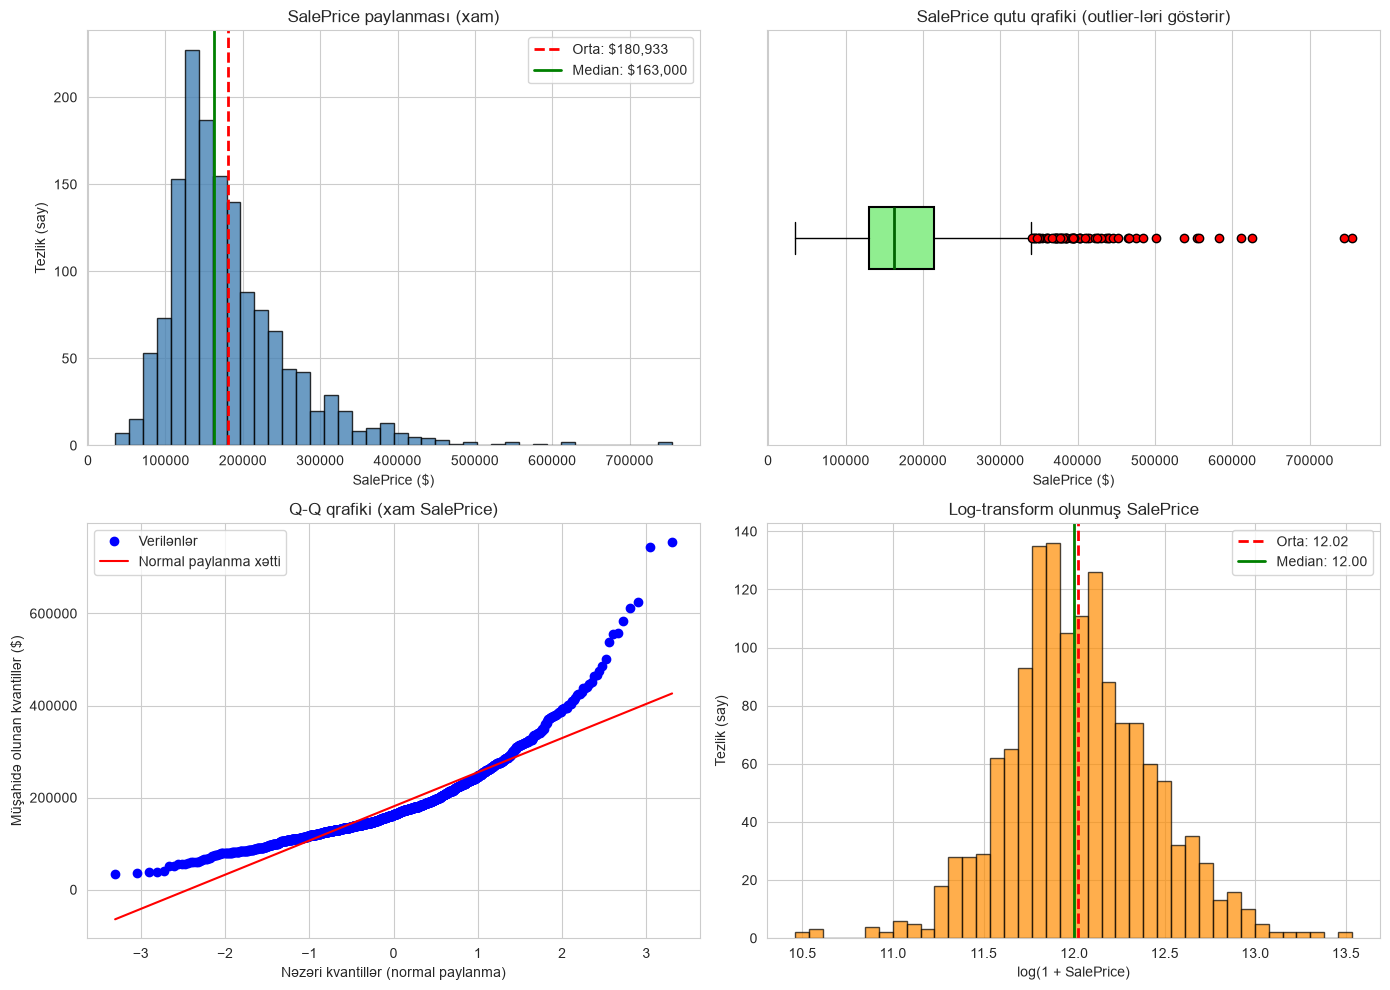

In [4]:
# TODO: Hədəf dəyişənin vizuallaşdırılması üçün 2x2 subplot yaradın
# 1. Orta və median xətləri olan histoqram
# 2. Box plot (qutu qrafiki)
# 3. Q-Q qrafiki (stats.probplot() istifadə edin)
# 4. Loqarifmik transformasiya olunmuş histoqram
# 
# fig, axes = plt.subplots(2, 2, figsize=(14, 10)) istifadə edin
# Başlıqlar, oxların adları və legendlər əlavə edin
# plt.tight_layout() və plt.show() istifadə edin

y_raw = np.expm1(y) # real dollar qiymətləri

y_log = y # artıq log-transform olunub

fig , axes = plt.subplots(2 , 2 ,figsize = (14 , 10))

mean_raw = y_raw.mean()
median_raw = y_raw.median()

axes[0 , 0].hist(y_raw , bins=40 , color='steelblue' , edgecolor='black' , alpha=0.8)
axes[0 , 0].axvline(mean_raw , color = "red" , linestyle='--' , linewidth = 2, 
                    label=f'Orta: ${mean_raw:,.0f}')
axes[0, 0].axvline(median_raw, color='green', linestyle='-', linewidth=2,
                    label=f'Median: ${median_raw:,.0f}')
axes[0, 0].set_title('SalePrice paylanması (xam)')
axes[0, 0].set_xlabel('SalePrice ($)')
axes[0, 0].set_ylabel('Tezlik (say)')
axes[0, 0].legend()


# 2. Box plot 

axes[0, 1].boxplot(y_raw , vert=False , patch_artist = True , 
                    boxprops= dict(facecolor="lightgreen", edgecolor='black', linewidth=1.5) , 
                    medianprops = dict(color = 'darkgreen' , linewidth = 2),
                    flierprops = dict(marker = 'o' , markerfacecolor = 'red' , 
                    markersize=6))

axes[0, 1].set_title('SalePrice qutu qrafiki (outlier-ləri göstərir)')
axes[0, 1].set_xlabel('SalePrice ($)')
axes[0, 1].set_yticks([])   # tək qutu olduğu üçün y oxu lazım deyil

# 3. Q-Q qrafiki

stats.probplot(y_raw, dist='norm', plot=axes[1, 0])
axes[1, 0].set_title('Q-Q qrafiki (xam SalePrice)')
axes[1, 0].set_xlabel('Nəzəri kvantillər (normal paylanma)')
axes[1, 0].set_ylabel('Müşahidə olunan kvantillər ($)')
lines = axes[1, 0].get_lines()
lines[0].set_label('Verilənlər')
lines[1].set_label('Normal paylanma xətti')
axes[1, 0].legend()

# 4. Log-transform olunmuş histoqram 
mean_log   = y_log.mean()
median_log = y_log.median()

axes[1, 1].hist(y_log, bins=40, color='darkorange', edgecolor='black', alpha=0.7)
axes[1, 1].axvline(mean_log, color='red', linestyle='--', linewidth=2,
                label=f'Orta: {mean_log:.2f}')
axes[1, 1].axvline(median_log, color='green', linestyle='-', linewidth=2,
                label=f'Median: {median_log:.2f}')
axes[1, 1].set_title('Log-transform olunmuş SalePrice')
axes[1, 1].set_xlabel('log(1 + SalePrice)')
axes[1, 1].set_ylabel('Tezlik (say)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()





### Sizin Təhlil:

Hədəf dəyişən haqqında müşahidələrinizi yazın:
- Paylanma normaldır, yoxsa əyridir?
- Kənar qiymətlər (outliers) varmı?
- Evlərin əksəriyyəti hansı qiymət aralığına düşür?
- Loqarifmik transformasiya normallığı yaxşılaşdırırmı?

---
## Tapşırıq 3: Birdəyişənli Təhlil - Say Xüsusiyyətləri

Fərdi say xüsusiyyətlərini təhlil edin.

In [5]:
# TODO: Say xüsusiyyətlərini əldə edin
# - int64 və float64 tipli sütunları almaq üçün select_dtypes istifadə edin

numerical_features = df_clean.select_dtypes(include=['int64' , 'float64']).columns.tolist()

# - 'Id' sütunu varsa, silin

if "Id" in numerical_features:
    numerical_features.remove('Id')

# - 'SalePrice' varsa, silin (onu ayrıca təhlil edəcəyik)

if "SalePrice" in numerical_features:
    numerical_features.remove("SalePrice")


# - numerical_features siyahısında saxlayın

print(f"Təhlil edilən say xüsusiyyətlərinin sayı: {len(numerical_features)}")
print(numerical_features)

# TODO: Təhlil edilən say xüsusiyyətlərinin sayını çap edin


Təhlil edilən say xüsusiyyətlərinin sayı: 36
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']


### Addım 3.1: Əsas Say Xüsusiyyətlərinin Paylanma Təhlili

Təhlil ediləcək xüsusiyyətlər: ['GrLivArea', 'TotalBsmtSF', 'LotArea', 'GarageArea', 'YearBuilt']


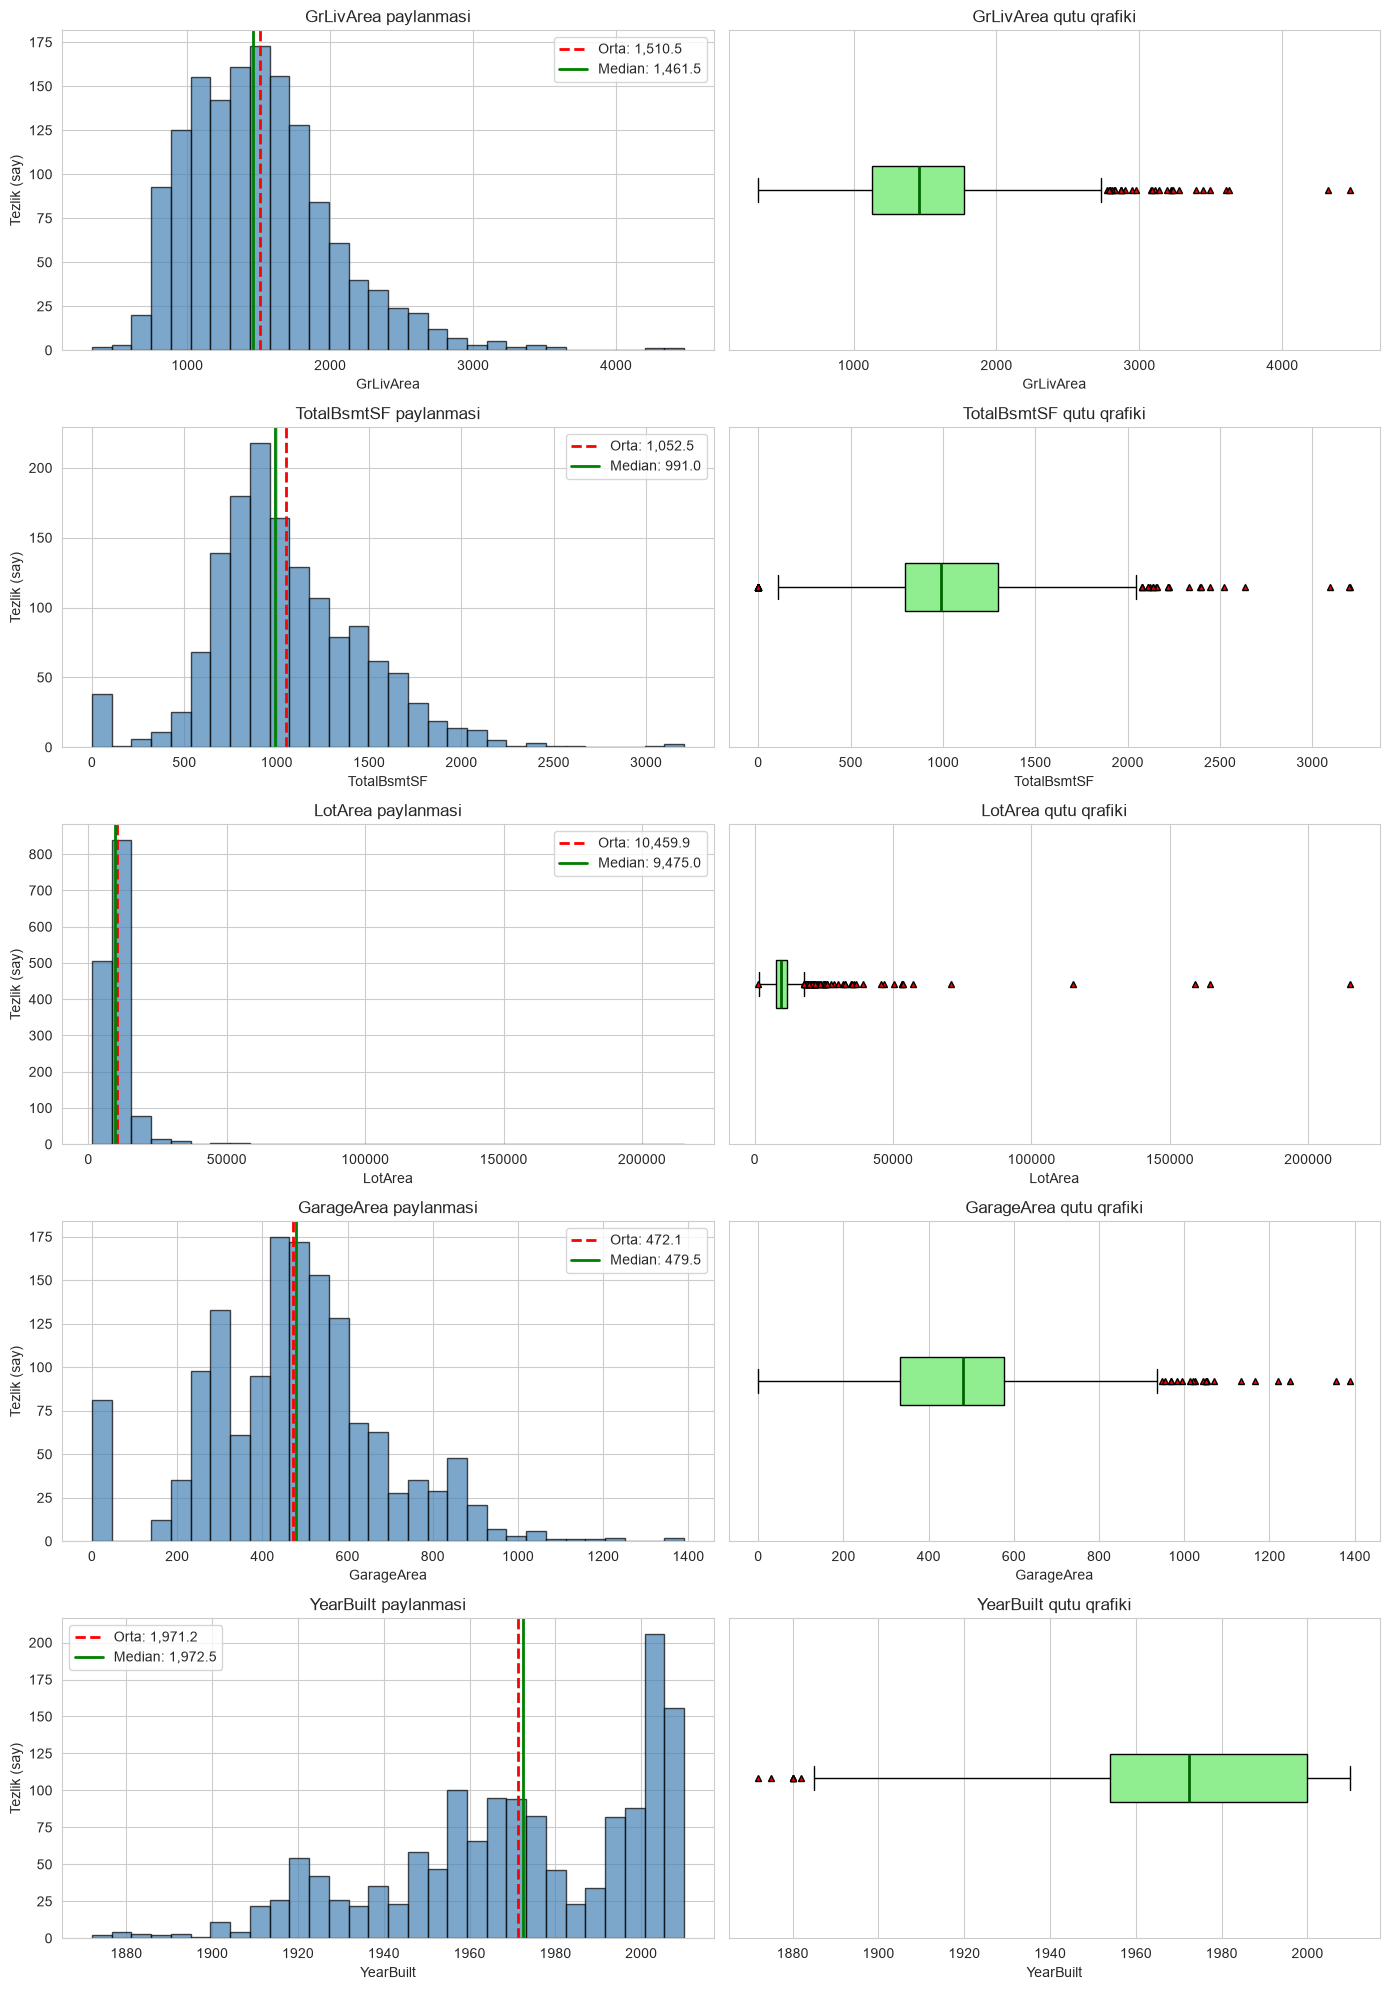

GrLivArea    əvvəl:   1.01   log1p sonra:  -0.07
LotArea      əvvəl:  12.56   log1p sonra:  -0.18


In [6]:
# TODO: Təhlil ediləcək əsas xüsusiyyətləri seçin
# Nümunələr: GrLivArea, TotalBsmtSF, LotArea, GarageArea, YearBuilt
# - df_original-də mövcud olan xüsusiyyətləri süzün
# - key_features siyahısında saxlayın

df_original = df_clean.copy()

candidate_features = ['GrLivArea', 'TotalBsmtSF', 'LotArea', 'GarageArea', 'YearBuilt']

key_features = [f for f in candidate_features if f in df_original.columns]
print(f"Təhlil ediləcək xüsusiyyətlər: {key_features}")



# TODO: Paylanma qrafikləri yaradın
# - 2 sütunlu subplot-lar yaradın (histoqram və boxplot)
# - Hər xüsusiyyət üçün:
#   * Sol: 30 bin (bins) ilə histoqram
#   * Orta və median xətləri əlavə edin
#   * Sağ: Boxplot
# - tight_layout istifadə edin və göstərin
    
n = len(key_features)

fig , axes = plt.subplots(n , 2 , figsize=(14 , 4 * n) , squeeze=False)

for i , features in enumerate(key_features):
    data = df_original[features].dropna()
    mean_val = data.mean()
    median_val = data.median()

    axes[i][0].hist(data , bins = 30 , color = "steelblue"
                    ,edgecolor='black', alpha=0.7)
    axes[i, 0].axvline(mean_val, color='red', linestyle='--', linewidth=2,
                    label=f'Orta: {mean_val:,.1f}')
    axes[i, 0].axvline(median_val, color='green', linestyle='-', linewidth=2,
                    label=f'Median: {median_val:,.1f}')

    axes[i][0].set_title(f"{features} paylanmasi")
    axes[i][0].set_xlabel(features)
    axes[i][0].set_ylabel("Tezlik (say)")
    axes[i][0].legend()

    axes[i][1].boxplot(data , vert= False , patch_artist = True ,
                    boxprops = dict(facecolor = "lightgreen") ,
                    medianprops = dict(color="darkgreen" , linewidth =2) ,
                    flierprops = dict(marker = '^' , markerfacecolor = 'red' , 
                                    markersize = 4))
    axes[i, 1].set_title(f'{features} qutu qrafiki')
    axes[i, 1].set_xlabel(features)
    axes[i, 1].set_yticks([])

plt.tight_layout()
plt.show()


for f in ['GrLivArea','LotArea']:
    s = df_original[f]
    print(f"{f:<12} əvvəl: {stats.skew(s):6.2f}   log1p sonra: {stats.skew(np.log1p(s)):6.2f}")


---
## Tapşırıq 4: Birdəyişənli Təhlil - Kateqorial Xüsusiyyətlər

Kateqorial dəyişənlərin paylanmalarını təhlil edin.

In [7]:
# TODO: Kateqorial xüsusiyyətləri əldə edin
# - 'object' sütunlarını almaq üçün select_dtypes istifadə edin
# - categorical_features siyahısında saxlayın

# TODO: Kateqorial xüsusiyyətlərin sayını çap edin
# TODO: Hər kateqorial xüsusiyyət üçün unikal dəyərlərin sayını çap edin

categorical_features = df_original.select_dtypes(include=['object']).columns.tolist()
print(f"Kateqorial xüsusiyyətlərin sayı: {len(categorical_features)}")

print("\nHər xüsusiyyət üçün unikal dəyərlərin sayı:")

for  i , features in enumerate(categorical_features):
    print(f" {features} :  {df_original[features].nunique()}")

Kateqorial xüsusiyyətlərin sayı: 39

Hər xüsusiyyət üçün unikal dəyərlərin sayı:
 MSZoning :  5
 Street :  2
 LotShape :  4
 LandContour :  4
 Utilities :  2
 LotConfig :  5
 LandSlope :  3
 Neighborhood :  25
 Condition1 :  9
 Condition2 :  8
 BldgType :  5
 HouseStyle :  8
 RoofStyle :  6
 RoofMatl :  7
 Exterior1st :  15
 Exterior2nd :  16
 MasVnrType :  4
 ExterQual :  4
 ExterCond :  5
 Foundation :  6
 BsmtQual :  5
 BsmtCond :  5
 BsmtExposure :  5
 BsmtFinType1 :  7
 BsmtFinType2 :  7
 Heating :  6
 HeatingQC :  5
 CentralAir :  2
 Electrical :  5
 KitchenQual :  4
 Functional :  7
 FireplaceQu :  6
 GarageType :  7
 GarageFinish :  4
 GarageQual :  6
 GarageCond :  6
 PavedDrive :  3
 SaleType :  9
 SaleCondition :  6


### Addım 4.1: Əsas Kateqorial Xüsusiyyətlərin Vizuallaşdırılması

Seçilən xüsusiyyətlər: ['MSZoning', 'LotConfig', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle']


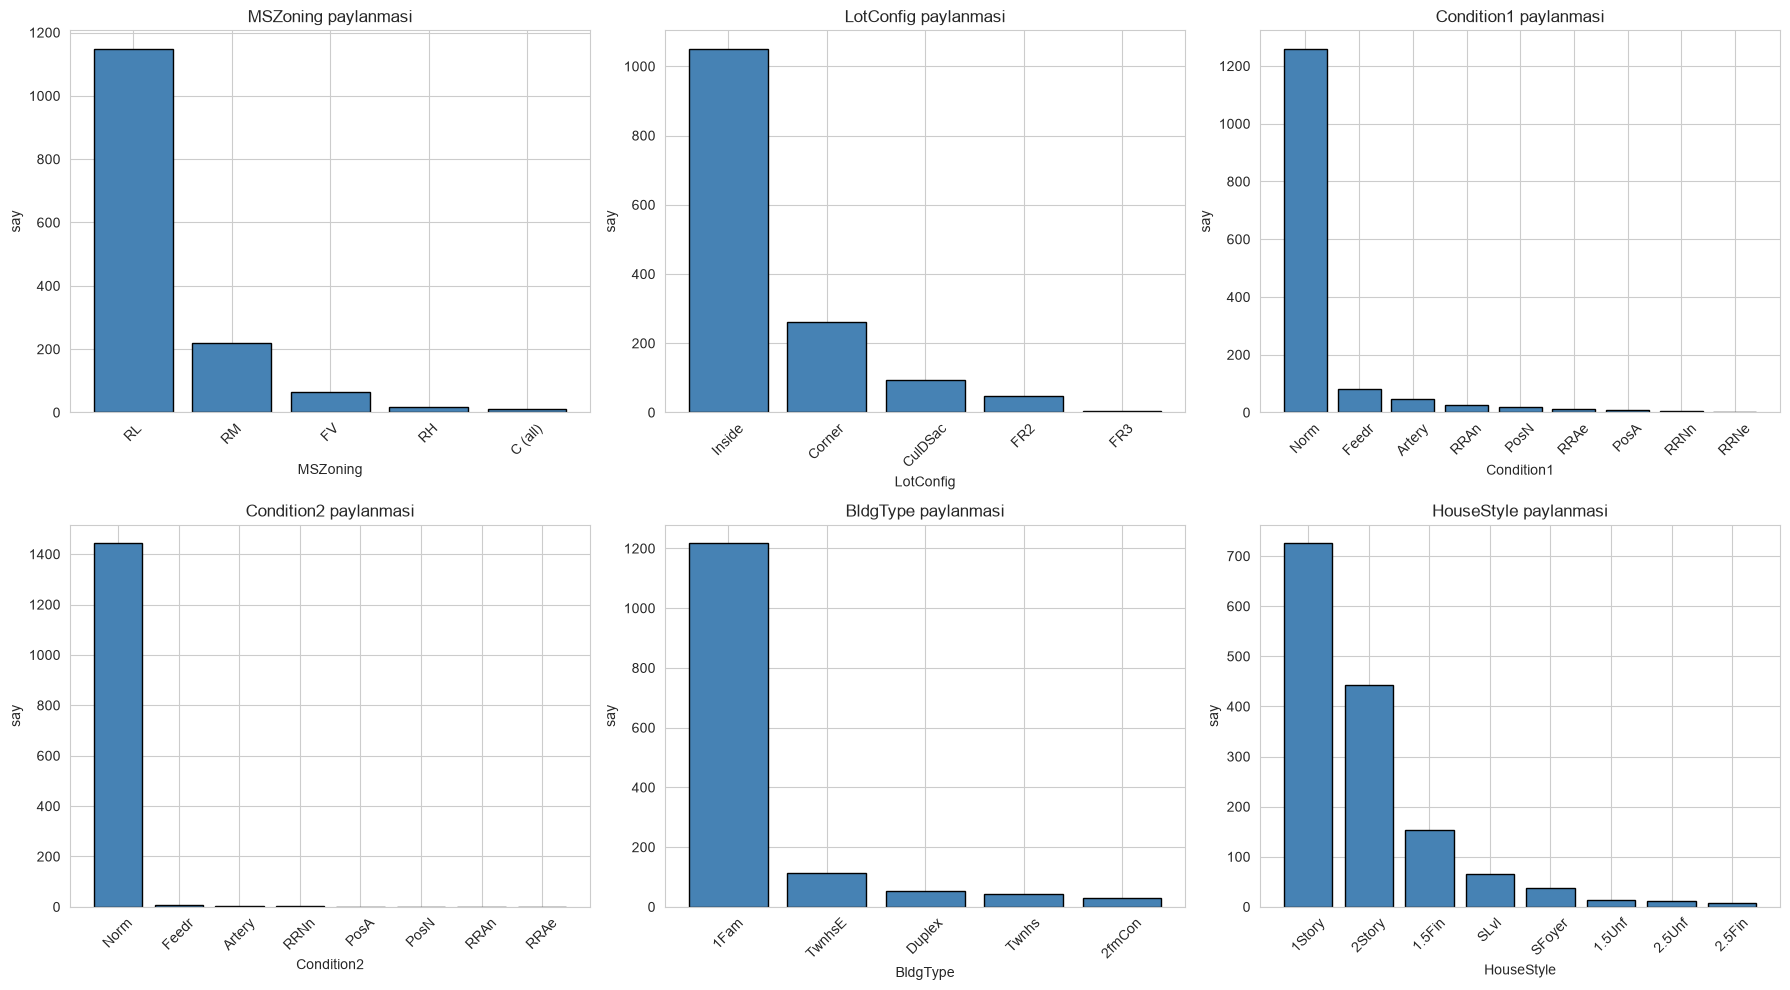

MSZoning        dominant pay: 78.8%   kateqoriya sayı: 5
Street          dominant pay: 99.6%   kateqoriya sayı: 2
LotShape        dominant pay: 63.4%   kateqoriya sayı: 4
LandContour     dominant pay: 89.9%   kateqoriya sayı: 4
Utilities       dominant pay: 99.9%   kateqoriya sayı: 2
LotConfig       dominant pay: 72.1%   kateqoriya sayı: 5
LandSlope       dominant pay: 94.7%   kateqoriya sayı: 3
Neighborhood    dominant pay: 15.4%   kateqoriya sayı: 25
Condition1      dominant pay: 86.4%   kateqoriya sayı: 9
Condition2      dominant pay: 99.0%   kateqoriya sayı: 8
BldgType        dominant pay: 83.5%   kateqoriya sayı: 5
HouseStyle      dominant pay: 49.8%   kateqoriya sayı: 8
RoofStyle       dominant pay: 78.3%   kateqoriya sayı: 6
RoofMatl        dominant pay: 98.3%   kateqoriya sayı: 7
Exterior1st     dominant pay: 35.3%   kateqoriya sayı: 15
Exterior2nd     dominant pay: 34.6%   kateqoriya sayı: 16
MasVnrType      dominant pay: 59.8%   kateqoriya sayı: 4
ExterQual       dominant pay

In [8]:
# TODO: Əsas kateqorial xüsusiyyətləri seçin
# - Orta kardinallığa (5-15 unikal dəyər) malik xüsusiyyətləri süzün
# - Vizuallaşdırma üçün 6 xüsusiyyətlə məhdudlaşdırın

mid_cardinality = [f for f in categorical_features if 5 <= df_original[f].nunique() <= 15]
key_categorical = mid_cardinality[ : 6]
print(f"Seçilən xüsusiyyətlər: {key_categorical}")


# TODO: Sütunlu qrafiklər (bar plot) yaradın
# - 2x3 subplot şəbəkəsi yaradın
# - Hər xüsusiyyət üçün:
#   * Dəyərlərin sayını (value counts) əldə edin
#   * Bar plot yaradın
#   * Oxunaqlıq üçün x-oxu yazılarını fırladın
# - İstifadə olunmayan subplot-ları gizlədin
# - Fiquru göstərin

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()   # 2D massivi 1D-yə çevirir: axes[0] ... axes[5]

for i , feature in enumerate(key_categorical):
    counts = df_original[feature].value_counts()

    axes[i].bar(counts.index.astype(str) , counts.values , color="steelblue" ,
                edgecolor = "black")
    axes[i].set_title(f'{feature} paylanmasi')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("say")
    axes[i].tick_params(axis = 'x' , rotation = 45)

for j in range(len(key_categorical) , len(axes)):
    axes[j].set_visible(False)

    
plt.tight_layout()
plt.show()


for f in categorical_features:
    share = df_original[f].value_counts(normalize=True).iloc[0]
    n_cat = df_original[f].nunique()
    print(f"{f:<15} dominant pay: {share:.1%}   kateqoriya sayı: {n_cat}")

---
## Tapşırıq 5: İkidəyişənli Təhlil - Say Xüsusiyyətləri və Hədəf

Say xüsusiyyətləri ilə SalePrice arasındakı əlaqələri təhlil edin.

### Addım 5.1: Korrelyasiya Təhlili

In [9]:
# TODO: Korrelyasiyaları hesablayın
# - Say sütunlarını seçin
# - Korrelyasiya matrisini hesablayın
# - 'SalePrice' ilə korrelyasiyaları çıxarın
# - Azalan sıra ilə düzün

# TODO: SalePrice ilə ən çox korrelyasiya edən ilk 15 xüsusiyyəti çap edin

df_corr = df_original[numerical_features].copy()
df_corr["SalePrice"] = y.values
corr_matrix = df_corr.corr()

saleprice_corr = corr_matrix['SalePrice'].sort_values(ascending=False)
print(saleprice_corr)


SalePrice        1.000000
OverallQual      0.821405
GrLivArea        0.725211
GarageCars       0.681033
GarageArea       0.656129
TotalBsmtSF      0.647563
1stFlrSF         0.620500
FullBath         0.595899
YearBuilt        0.587043
YearRemodAdd     0.565992
TotRmsAbvGrd     0.537702
Fireplaces       0.491998
MasVnrArea       0.430570
BsmtFinSF1       0.392283
LotFrontage      0.351551
GarageYrBlt      0.349013
WoodDeckSF       0.334251
OpenPorchSF      0.325215
2ndFlrSF         0.319953
HalfBath         0.314186
LotArea          0.260544
BsmtFullBath     0.237099
BsmtUnfSF        0.221892
BedroomAbvGr     0.209035
ScreenPorch      0.121245
PoolArea         0.074338
MoSold           0.057064
3SsnPorch        0.054914
BsmtFinSF2       0.004863
BsmtHalfBath    -0.005124
MiscVal         -0.020012
OverallCond     -0.036821
YrSold          -0.037151
LowQualFinSF    -0.037951
MSSubClass      -0.073969
KitchenAbvGr    -0.147534
EnclosedPorch   -0.149029
Name: SalePrice, dtype: float64


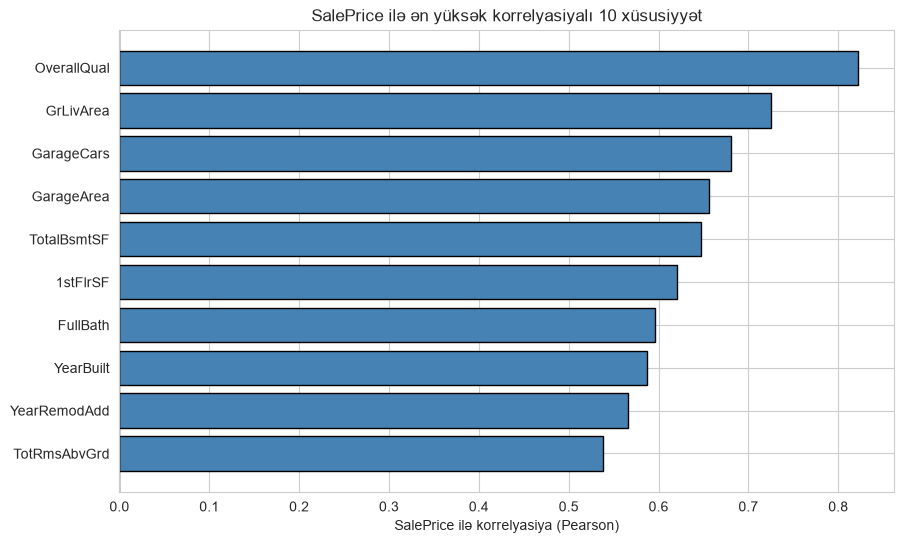

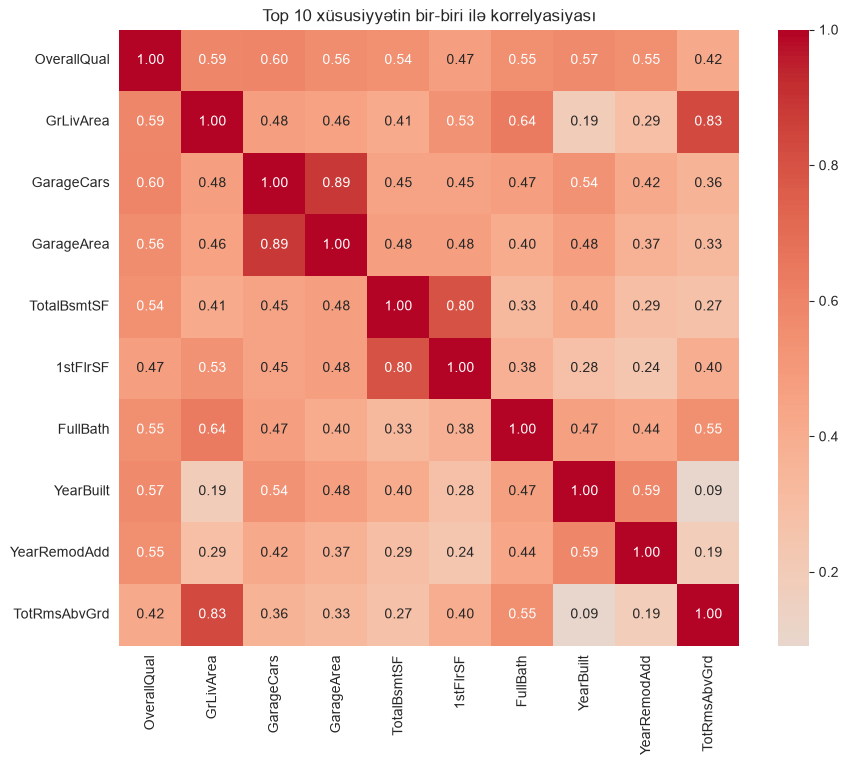

In [10]:
# TODO: Ən yüksək korrelyasiyaları vizuallaşdırın
# - İlk 10 xüsusiyyəti əldə edin (SalePrice-ın özü istisna olmaqla)
# - Üfüqi bar plot yaradın (figsize=(10, 6))
# - xlabel, title əlavə edin
# - x=0 nöqtəsində şaquli xətt əlavə edin
# - Qrafiki göstərin

top10 = saleprice_corr.drop('SalePrice').head(10)

plt.figure(figsize = (10 , 6))
plt.barh(top10.index[::-1] , top10.values[::-1] , color = 'steelblue' ,edgecolor='black')
plt.xlabel('SalePrice ilə korrelyasiya (Pearson)')
plt.title('SalePrice ilə ən yüksək korrelyasiyalı 10 xüsusiyyət')

plt.axvline(x = 0 , color= 'black' , linewidth = 1)
plt.show()

top10_features = top10.index.tolist()
plt.figure(figsize=(10, 8))
sns.heatmap(df_corr[top10_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Top 10 xüsusiyyətin bir-biri ilə korrelyasiyası')
plt.show()

### Addım 5.2: Ən Yaxşı Xüsusiyyətlərin SalePrice ilə Səpələnmə Qrafikləri (Scatter Plots)

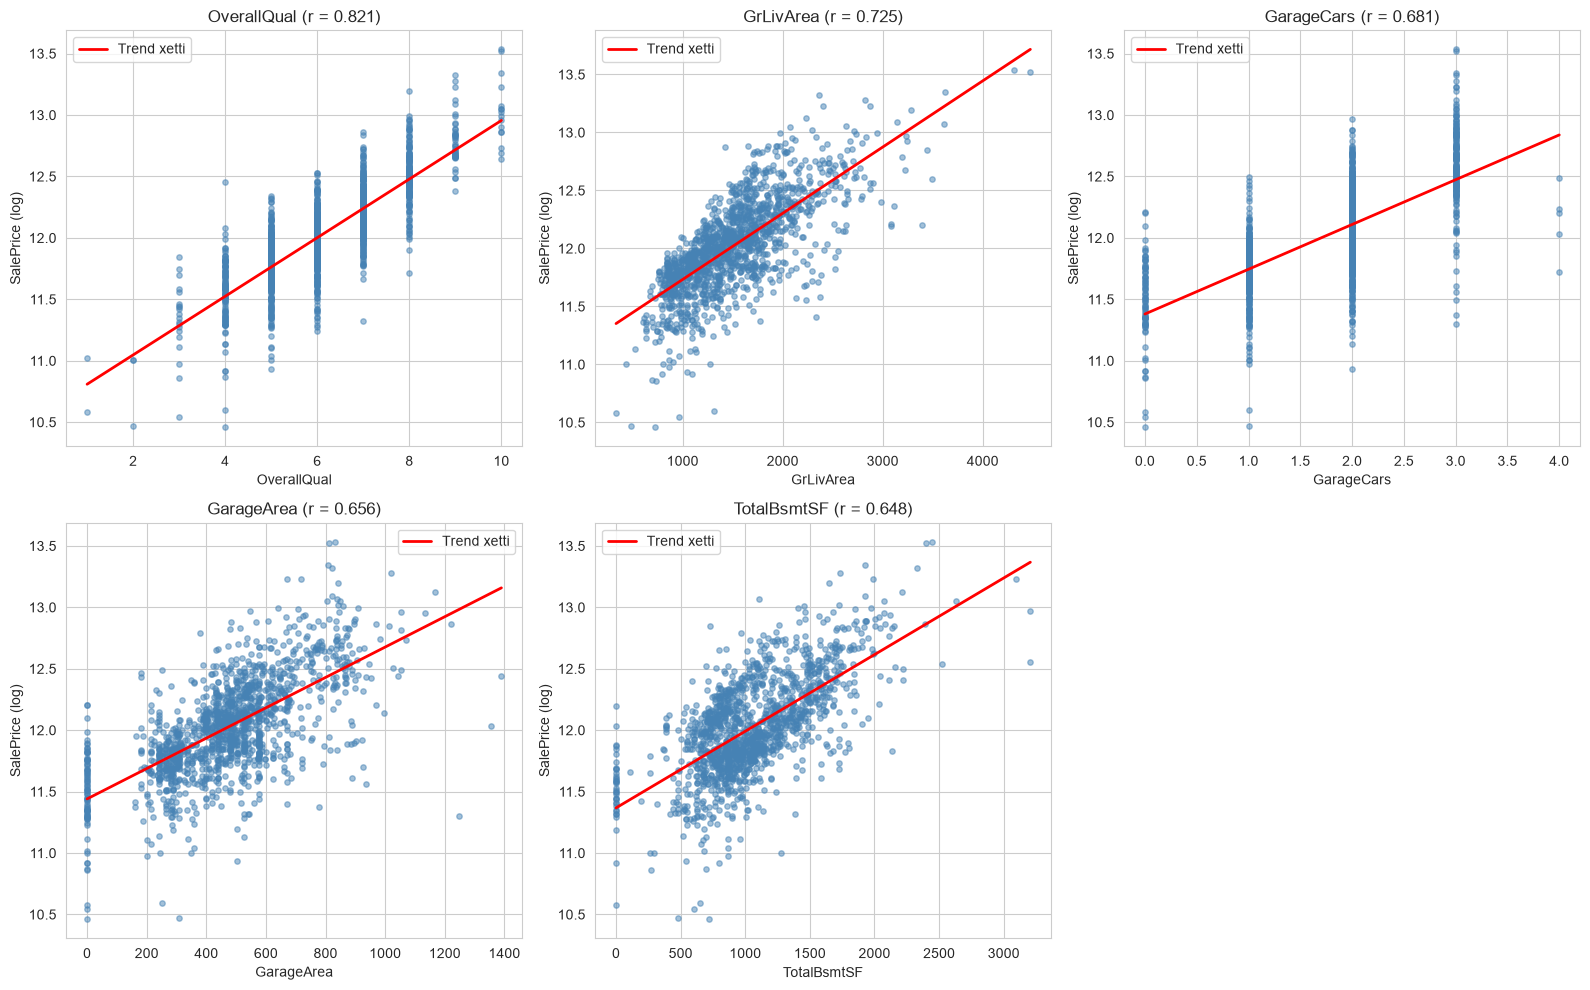

In [11]:
# TODO: Ən çox korrelyasiya edən ilk 5 xüsusiyyət üçün scatter plot-lar yaradın
# - 2x3 subplot şəbəkəsi yaradın (figsize=(16, 10))
# - İlk 5 xüsusiyyətin hər biri üçün:
#   * SalePrice ilə scatter plot yaradın
#   * np.polyfit ilə trend xətti əlavə edin
#   * Başlıqda korrelyasiya dəyərini göstərin
# - İstifadə olunmayan subplot-u gizlədin
# - Fiquru göstərin

top5 = saleprice_corr.drop("SalePrice").head(5).index.tolist()

fig , axes = plt.subplots(2 , 3 , figsize=(16 , 10))
axes = axes.flatten()

for i , feature in enumerate(top5):
    x = df_corr[feature]
    y_vals = df_corr["SalePrice"]

    axes[i].scatter(x , y_vals , alpha =0.5 , color = 'steelblue' , s = 15)

    slope , intercept = np.polyfit(x , y_vals , 1)
    x_line  = np.linspace(x.min() , x.max() , 100)
    axes[i].plot(x_line , slope * x_line + intercept , color = 'red',
                linewidth = 2 , label = 'Trend xetti')

    r = saleprice_corr[feature]
    axes[i].set_title(f'{feature} (r = {r:.3f})')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('SalePrice (log)')
    axes[i].legend()

    for j in range(len(top5) , len(axes)):
        axes[j].set_visible(False)
        
plt.tight_layout()
plt.show()




---
## Tapşırıq 6: İkidəyişənli Təhlil - Kateqorial Xüsusiyyətlər və Hədəf

Kateqorial xüsusiyyətlərin SalePrice-a necə təsir etdiyini təhlil edin.

['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'SaleType', 'SaleCondition']
Seçilən xüsusiyyətlər: ['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig']


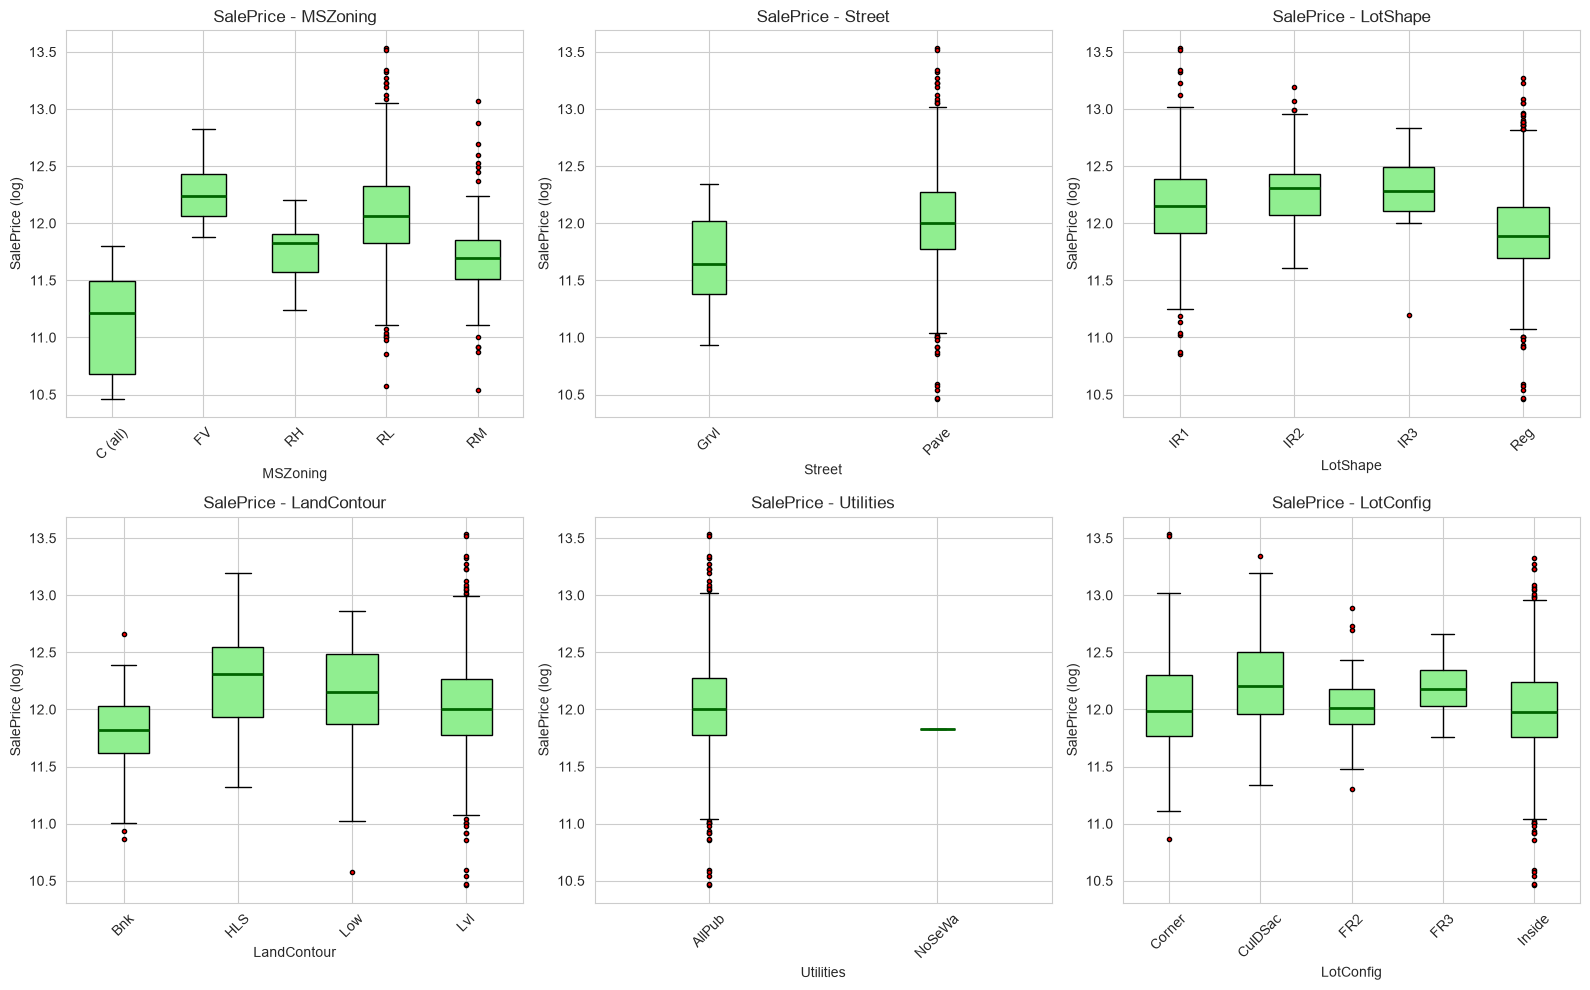

MSZoning
RL         1149
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64 

Street
Pave    1452
Grvl       6
Name: count, dtype: int64 

LotShape
Reg    925
IR1    483
IR2     41
IR3      9
Name: count, dtype: int64 

LandContour
Lvl    1311
Bnk      61
HLS      50
Low      36
Name: count, dtype: int64 

Utilities
AllPub    1457
NoSeWa       1
Name: count, dtype: int64 

LotConfig
Inside     1051
Corner      262
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64 



In [12]:
# TODO: Orta kardinallığa malik kateqorial xüsusiyyətləri seçin
# - 2-10 unikal dəyərə malik xüsusiyyətləri süzün
# - 6 xüsusiyyətlə məhdudlaşdırın

low_mid_cardinality = [
    f for f in categorical_features if 2 <= df_original[f].nunique() <= 10
]
print(low_mid_cardinality)

box_features = low_mid_cardinality[:6]
print(f"Seçilən xüsusiyyətlər: {box_features}")

# TODO: Box plot-lar yaradın
# - 2x3 subplot şəbəkəsi yaradın (figsize=(16, 10))
# - Hər xüsusiyyət üçün:
#   * SalePrice-ın kateqoriyalara görə boxplot-unu yaradın
#   * Oxunaqlıq üçün x-oxu yazılarını fırladın
# - İstifadə olunmayan subplot-ları gizlədin
# - Fiquru göstərin


df_box = df_original[box_features].copy()
df_box["SalePrice"] = y.values

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i , feature in enumerate(box_features):
    groups = df_box.groupby(feature)["SalePrice"].apply(list)

    axes[i].boxplot(groups.values , patch_artist = True ,
                    boxprops = dict(facecolor = 'lightgreen'),
                    medianprops = dict(color = 'darkgreen' , linewidth = 2),
                    flierprops = dict(marker = 'o' , markerfacecolor = 'red' , markersize =3))


    axes[i].set_xticklabels(groups.index.astype(str) , rotation = 45)
    axes[i].set_title(f'SalePrice - {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('SalePrice (log)')

    for j in range(len(box_features) , len(axes)):
        axes[j].set_visible(False)

plt.tight_layout()
plt.show()
for f in box_features:
    print(df_original[f].value_counts(), '\n')


### Addım 6.1: Kateqoriyalar üzrə Statistik Təhlil

In [13]:
# TODO: Kateqoriyalar üzrə orta qiyməti təhlil edin
# - İlk 3 kateqorial xüsusiyyət üçün:
#   * Xüsusiyyətə görə qruplaşdırın (group by)
#   * SalePrice-ın say (count), orta (mean), median və standart sapmasını (std) hesablayın
#   * Orta dəyərə görə azalan sıra ilə düzün
#   * Statistika cədvəlini çap edin

first3 = categorical_features[:3]
print(f"Təhlil edilən xüsusiyyətlər: {first3}\n")

df_stats = df_original[first3].copy()
df_stats['SalePrice'] = y.values

for feature in first3:
    stats_table = df_stats.groupby(feature)["SalePrice"].agg(['count' , 'mean' , 'median' , 'std']).sort_values('mean' , ascending=False)

    print("=" * 50)
    print(f"{feature} üzrə SalePrice statistikası (log şkalası)")
    print("=" * 50)
    print(stats_table.round(3))
    print()


Təhlil edilən xüsusiyyətlər: ['MSZoning', 'Street', 'LotShape']

MSZoning üzrə SalePrice statistikası (log şkalası)
          count    mean  median    std
MSZoning                              
FV           65  12.247  12.235  0.231
RL         1149  12.086  12.067  0.377
RH           16  11.750  11.824  0.289
RM          218  11.693  11.699  0.316
C (all)      10  11.118  11.218  0.485

Street üzrə SalePrice statistikası (log şkalası)
        count    mean  median    std
Street                              
Pave     1452  12.025  12.002  0.399
Grvl        6  11.667  11.645  0.520

LotShape üzrə SalePrice statistikası (log şkalası)
          count    mean  median    std
LotShape                              
IR2          41  12.318  12.306  0.362
IR3           9  12.230  12.278  0.463
IR1         483  12.164  12.150  0.377
Reg         925  11.936  11.891  0.385



---
## Tapşırıq 7: Çoxdəyişənli Təhlil (Multivariate Analysis)

Bir neçə xüsusiyyət arasındakı əlaqələri eyni vaxtda araşdırın.

### Addım 7.1: Korrelyasiya İstilik Xəritəsi (Heatmap)

['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'YearBuilt', 'YearRemodAdd', 'TotRmsAbvGrd']


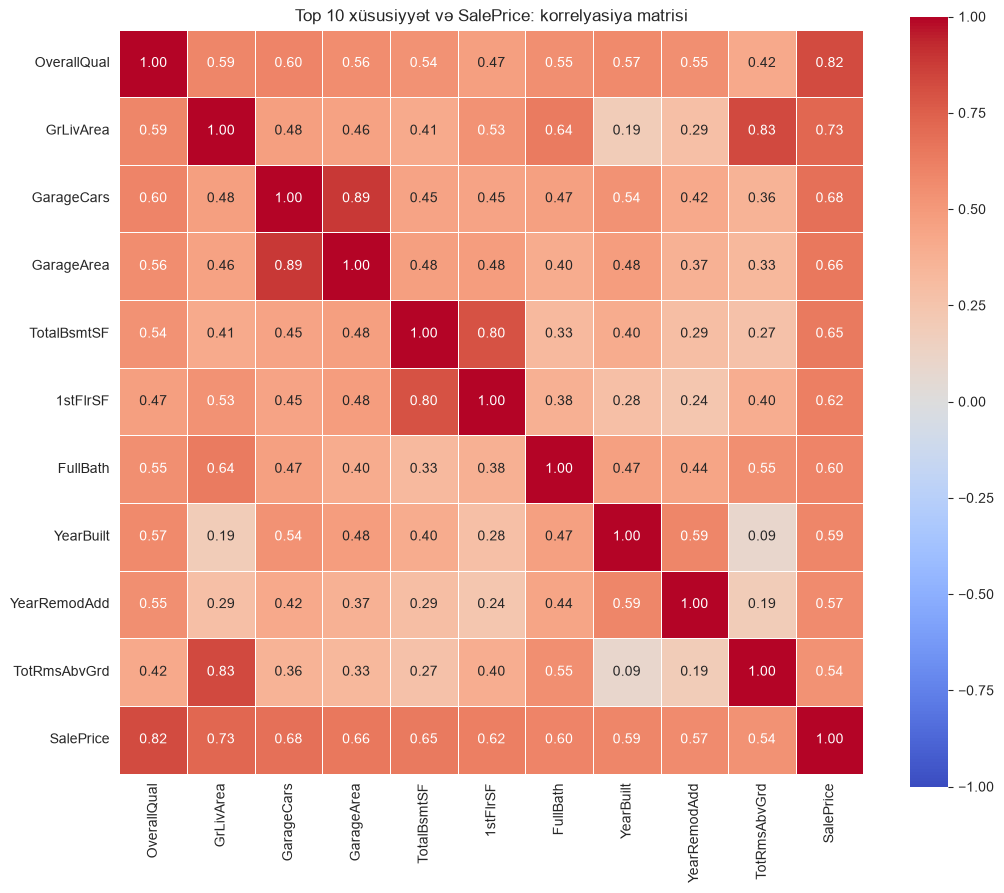

In [14]:
# TODO: Ən yaxşı xüsusiyyətlər üçün korrelyasiya heatmap-i yaradın
# - İlk 10-11 xüsusiyyəti və SalePrice-ı əldə edin
# - Korrelyasiya matrisi yaradın
# - seaborn ilə heatmap yaradın (figsize=(12, 10))
# - coolwarm rəng xəritəsindən (colormap) və annotasiyalardan istifadə edin
# - Başlıq əlavə edin və göstərin

top_features = saleprice_corr.drop("SalePrice").head(10).index.tolist()
print(top_features)

cols = top_features + ["SalePrice"]

corr_top = df_corr[cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_top,
            annot=True,        # hər xanaya rəqəmi yaz
            fmt='.2f',         # 2 onluq işarə
            cmap='coolwarm',   # mavi (mənfi) - ağ (0) - qırmızı (müsbət)
            center=0,          # rəng şkalasının ortası 0 olsun
            vmin=-1, vmax=1,   # şkala -1-dən 1-ə qədər
            square=True,       # xanalar kvadrat olsun
            linewidths=0.5)    # xanalar arasında nazik xətt
plt.title('Top 10 xüsusiyyət və SalePrice: korrelyasiya matrisi')
plt.show()



### Addım 7.2: Əsas Xüsusiyyətlərin Pair Plot-u

Seçilən sütunlar: ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'SalePrice']


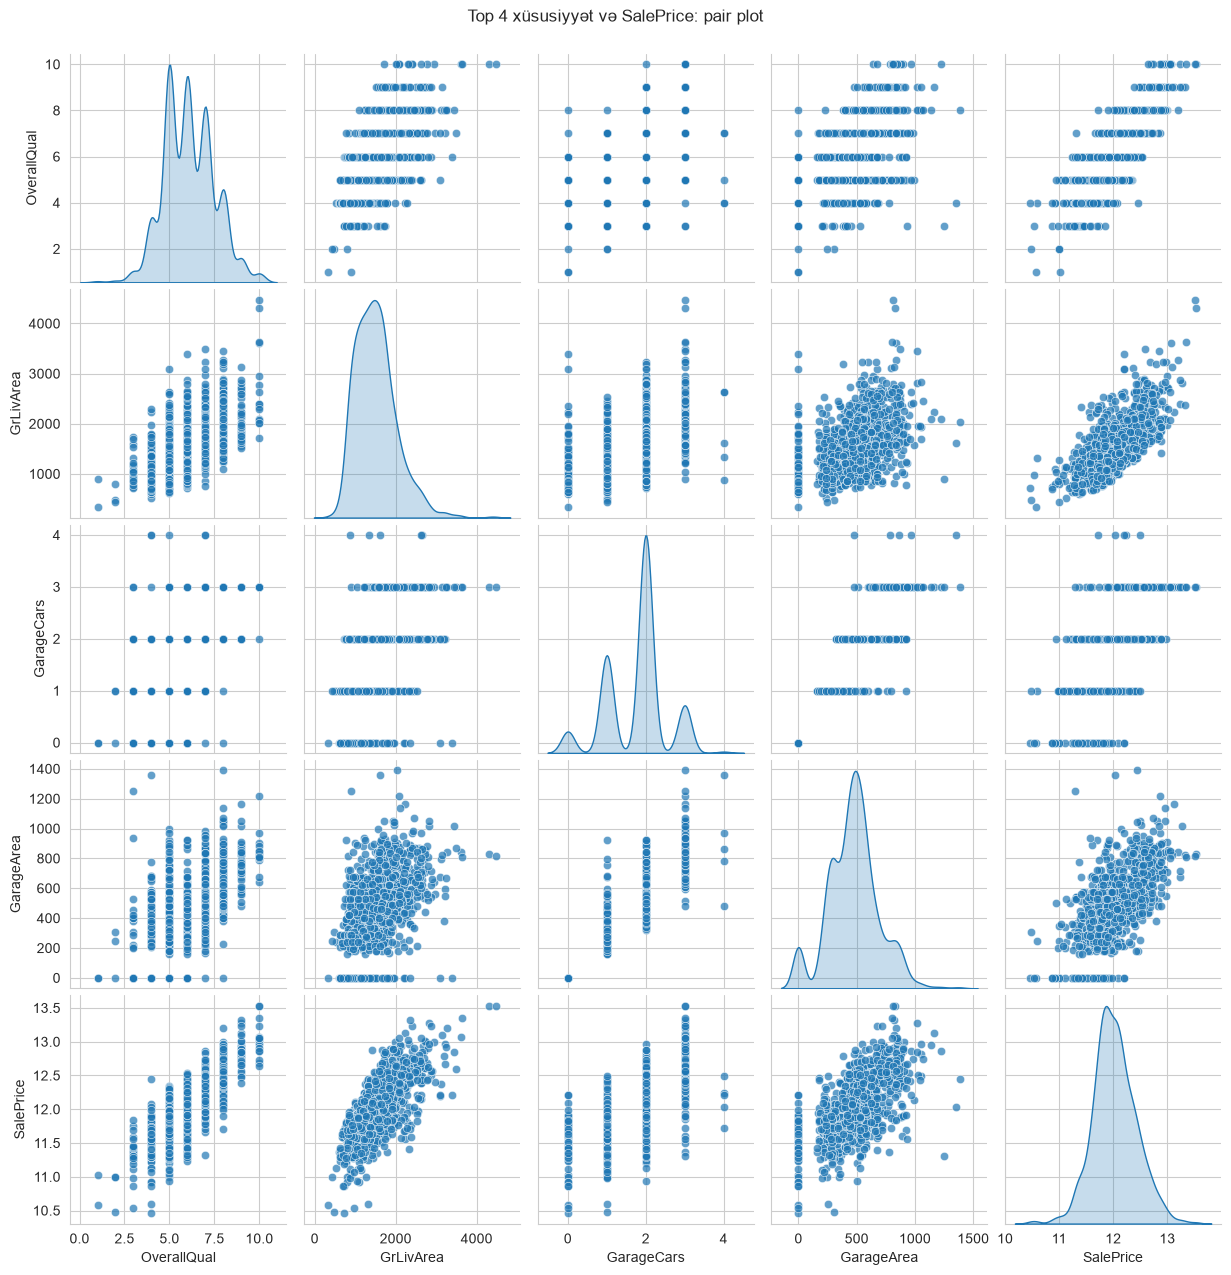

In [15]:
# TODO: Ən yaxşı xüsusiyyətlər üçün pair plot yaradın
# - İlk 4 xüsusiyyəti və SalePrice-ı seçin
# - Bu xüsusiyyətlərlə müvəqqəti dataframe yaradın
# - diag_kind='kde' ilə sns.pairplot istifadə edin
# - Qrafikin şəffaflığını təyin edin (alpha=0.6)
# - Başlıq əlavə edin və göstərin
# Qeyd: Bunun yaranması bir az vaxt apara bilər


top4 = saleprice_corr.drop("SalePrice").head(4).index.tolist()
cols = top4 + ["SalePrice"]
print(f"Seçilən sütunlar: {cols}")

df_pair = df_corr[cols].copy()

g = sns.pairplot(df_pair,diag_kind='kde' , plot_kws={'alpha' :0.7})
g.fig.suptitle('Top 4 xüsusiyyət və SalePrice: pair plot', y=1.02)
plt.show()




---
## Tapşırıq 8: Yaradılmış Xüsusiyyətlərin Təhlili

Mərhələ 3-də yaratdığınız xüsusiyyətləri qiymətləndirin.

In [16]:
# TODO: Mövcuddursa, yeni xüsusiyyətlərin siyahısını yükləyin
# - 'new_features_list.txt' faylını açmağa çalışın
# - Məzmunu oxuyun və çap edin
# - Fayl mövcud deyilsə, FileNotFoundError xətasını idarə edin
# Qeyd: Bu fayl Mərhələ 3-də yaradılır

try:
    with open('new_features_list.txt' , 'r' , encoding='utf-8') as f:
        content = f.read()
        print("new_features_list.txt faylının məzmunu:")
        print("=" * 50)
        print(content)
        
except FileNotFoundError:
    print("new_features_list.txt faylı tapılmadı.")


new_features_list.txt faylının məzmunu:
New Features Created:
1. TotalSF
2. TotalBath
3. TotalPorchSF
4. TotalRoomsAbvGrd
5. TotalQualScore
6. TotalFinishedSF
7. TotalUnfinishedSF
8. LivingArea_to_LotArea
9. Bsmt_to_TotalSF
10. Slope_to_LotArea
11. Garage_to_LivingArea
12. HouseAge
13. RemodAge
14. WasRemodeled
15. GarageAge
16. IsNew
17. HasSecondFloor
18. HasBasement
19. HasGarage
20. HasFireplace
21. HasPool
22. HasPorch
23. Quality_x_Area
24. Quality_x_Condition
25. Bath_x_Bedroom
26. NbhdQual
27. NbhdQual_x_Area
28. TotalQualScore_Squared



Aşkar edilən yeni xüsusiyyətlər: ['TotalSF', 'TotalBath', 'TotalQualScore', 'TotalFinishedSF', 'TotalUnfinishedSF', 'Slope_to_LotArea', 'HouseAge', 'RemodAge', 'IsNew', 'HasGarage', 'HasFireplace', 'HasPorch', 'Quality_x_Area', 'Quality_x_Condition', 'NbhdQual']



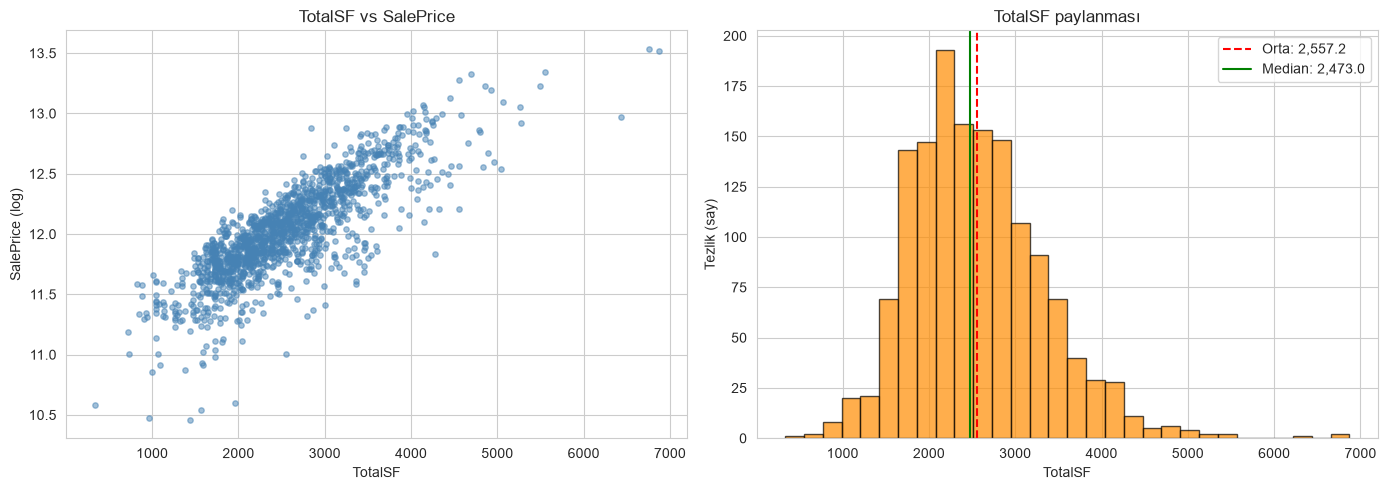

TotalSF ilə SalePrice korrelyasiyası: 0.825


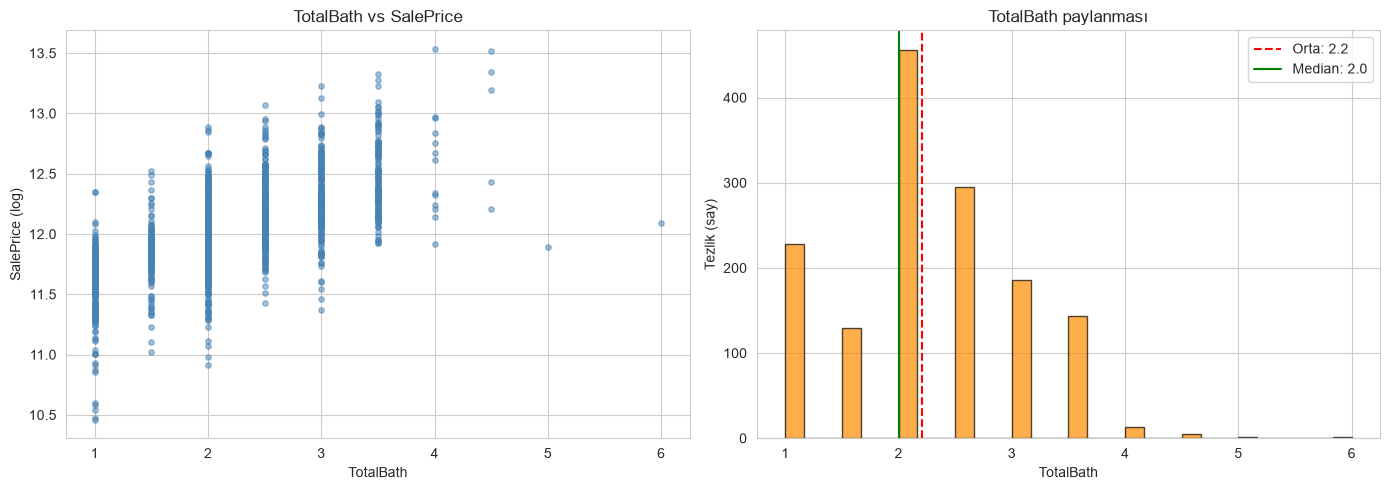

TotalBath ilə SalePrice korrelyasiyası: 0.677


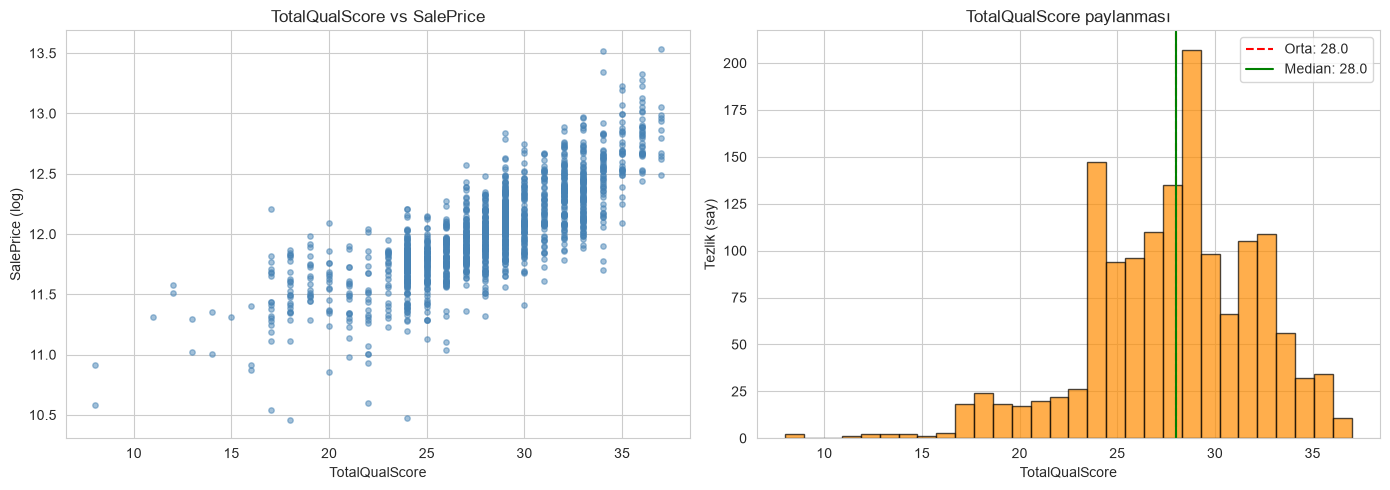

TotalQualScore ilə SalePrice korrelyasiyası: 0.792


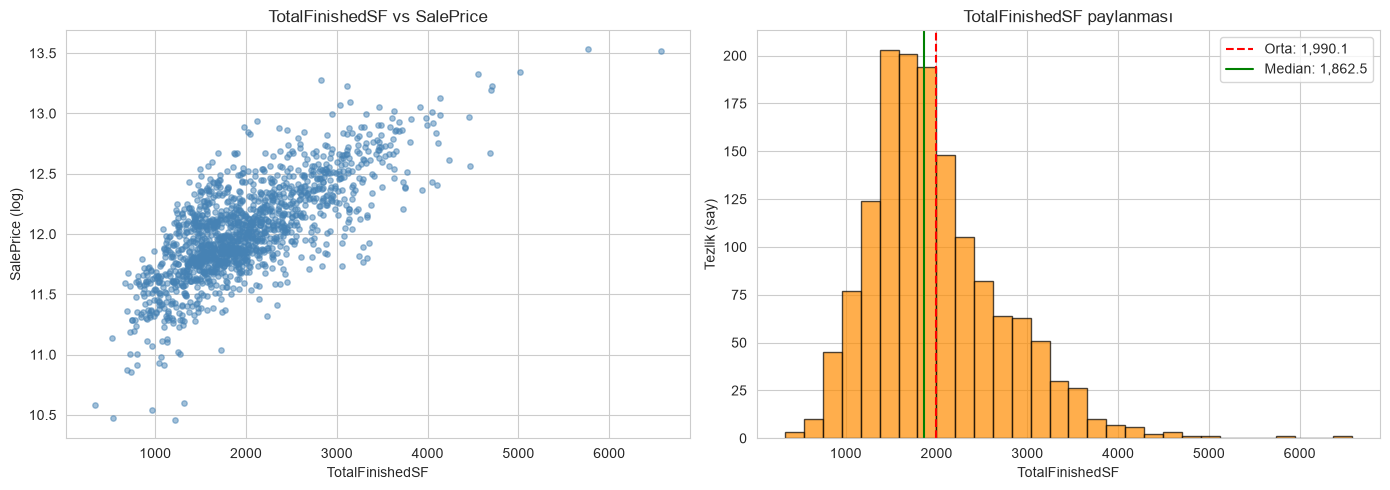

TotalFinishedSF ilə SalePrice korrelyasiyası: 0.747


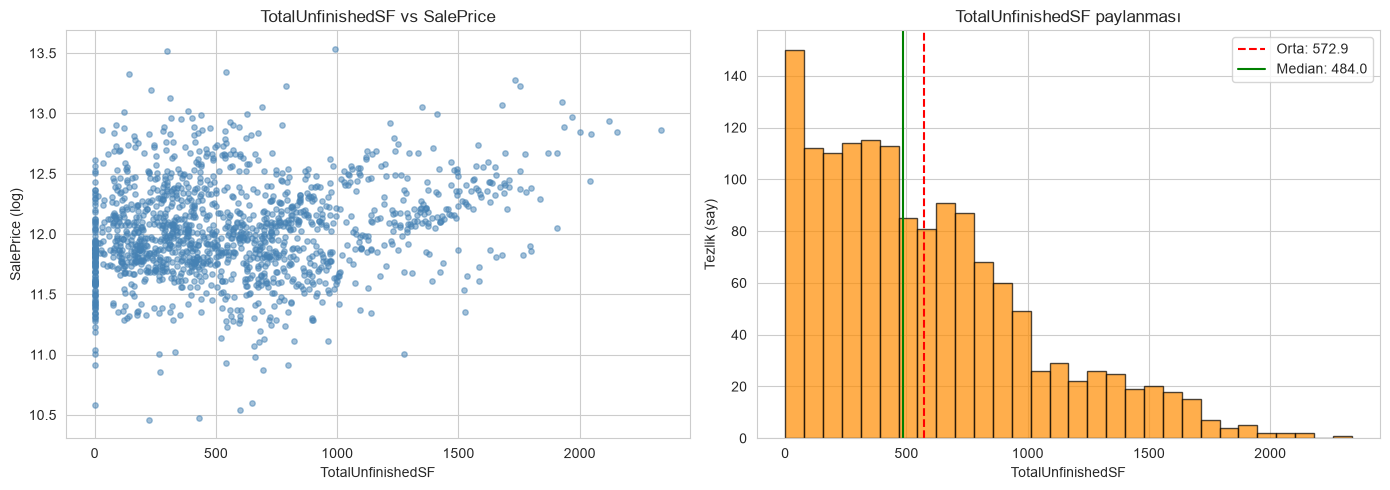

TotalUnfinishedSF ilə SalePrice korrelyasiyası: 0.216


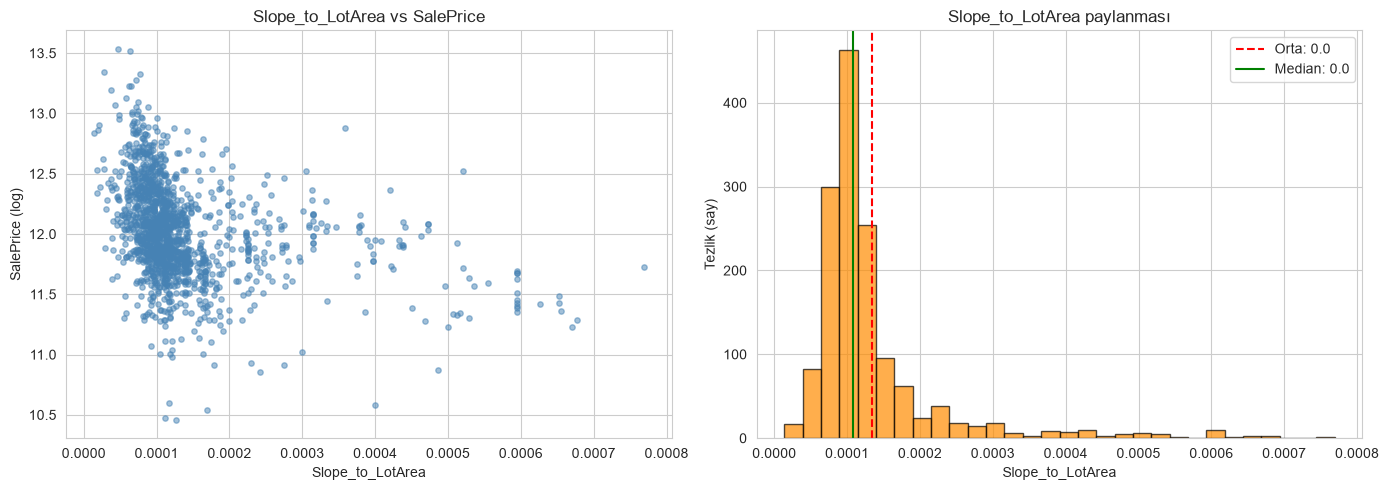

Slope_to_LotArea ilə SalePrice korrelyasiyası: -0.321


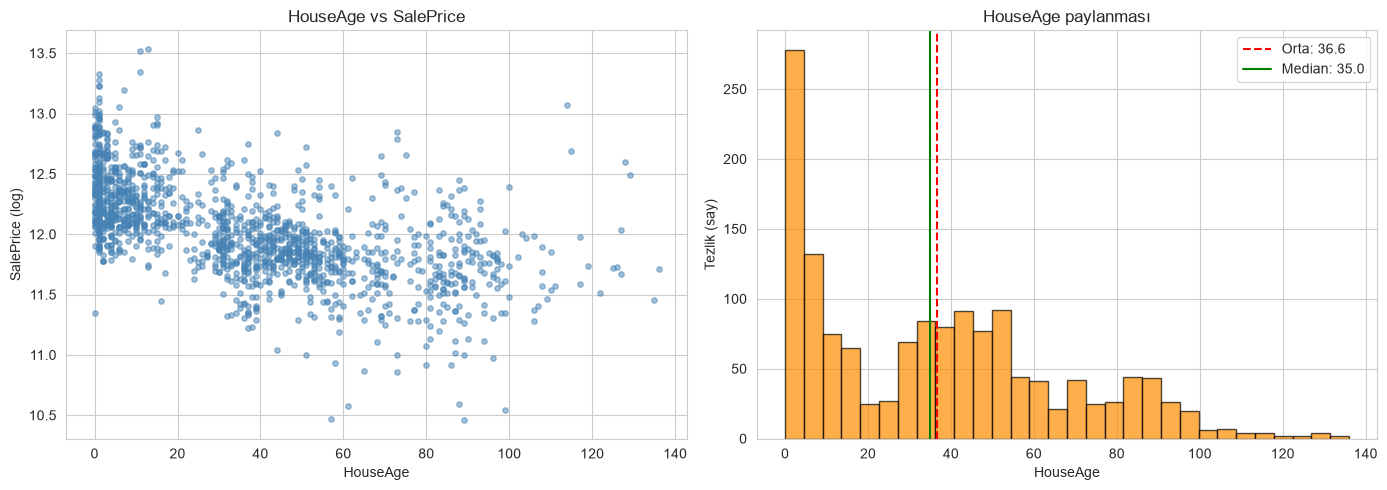

HouseAge ilə SalePrice korrelyasiyası: -0.588


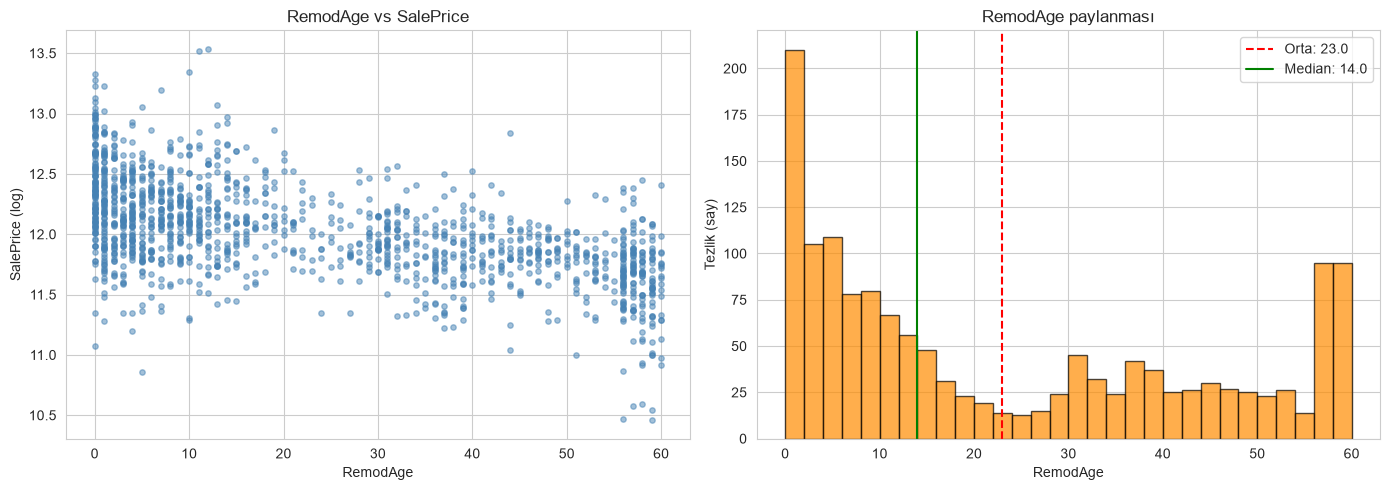

RemodAge ilə SalePrice korrelyasiyası: -0.569


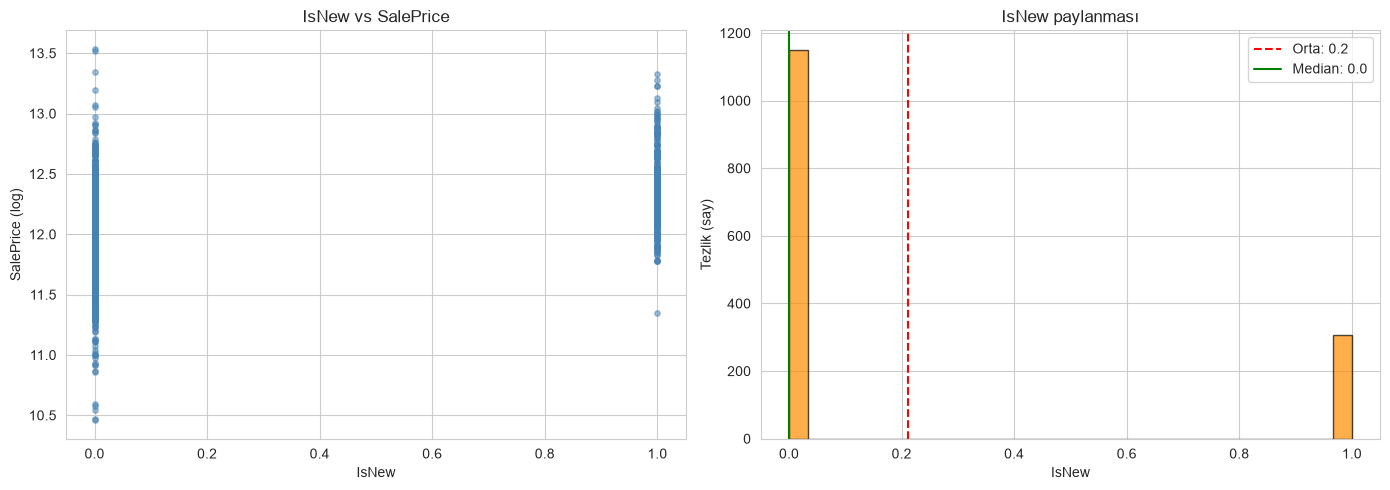

IsNew ilə SalePrice korrelyasiyası: 0.443


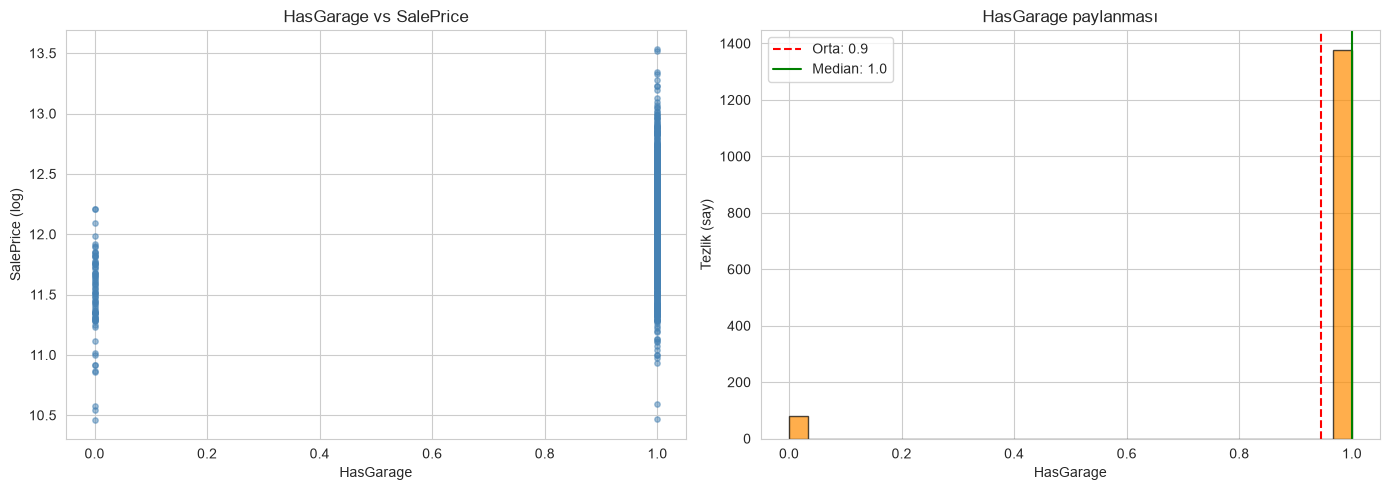

HasGarage ilə SalePrice korrelyasiyası: 0.323


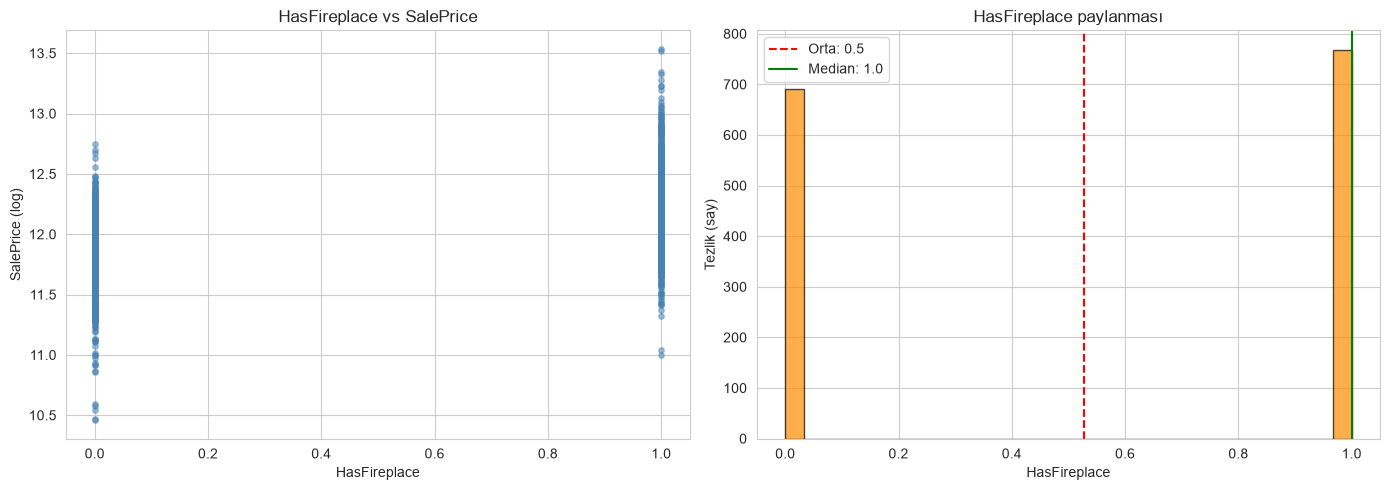

HasFireplace ilə SalePrice korrelyasiyası: 0.510


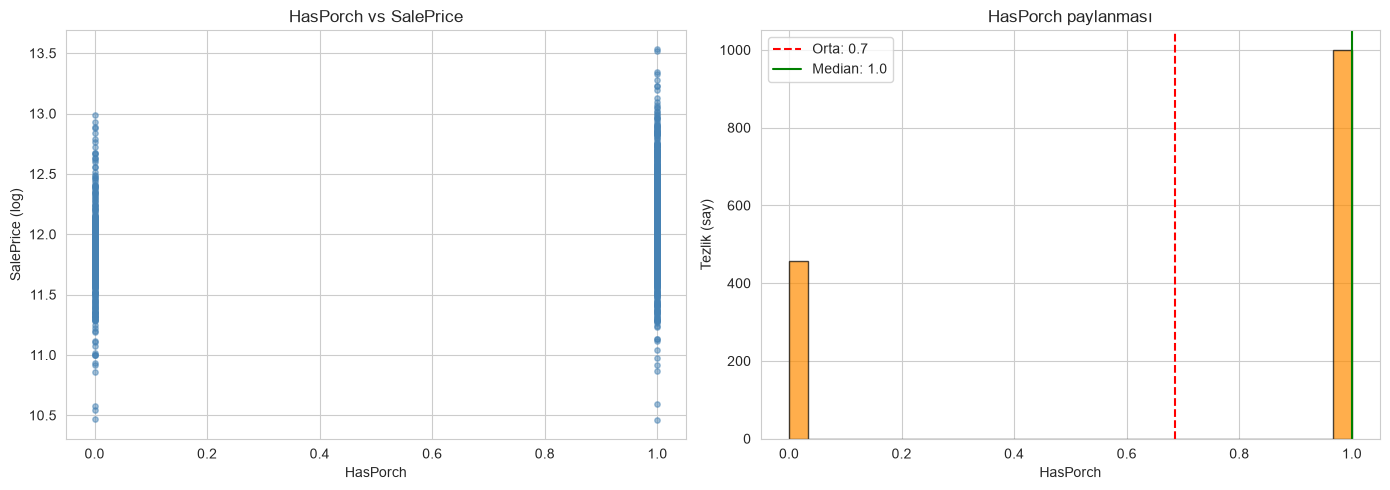

HasPorch ilə SalePrice korrelyasiyası: 0.327


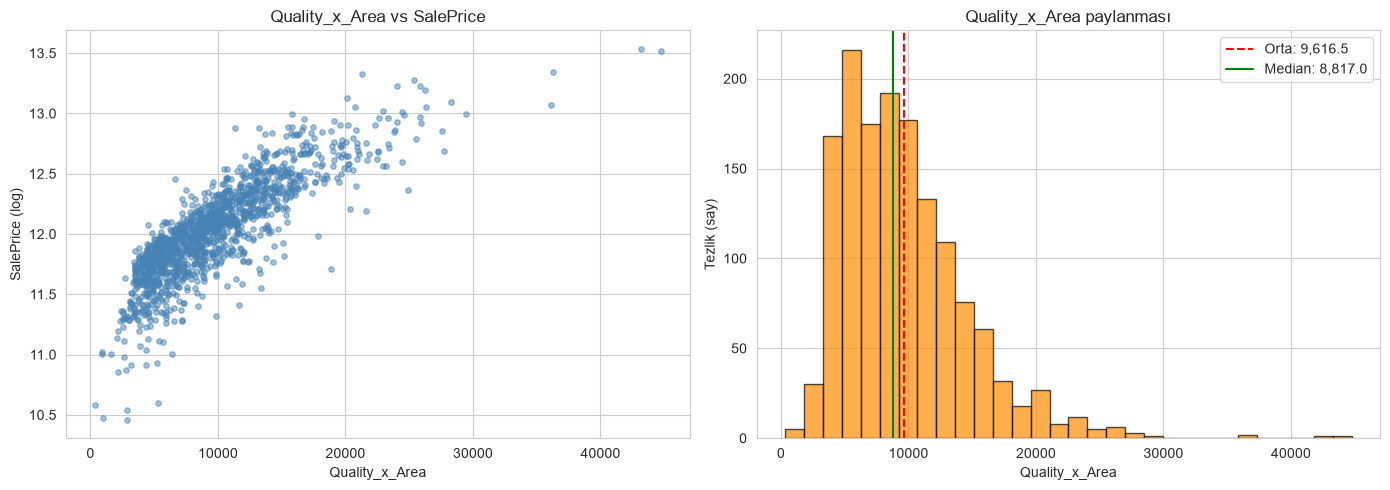

Quality_x_Area ilə SalePrice korrelyasiyası: 0.838


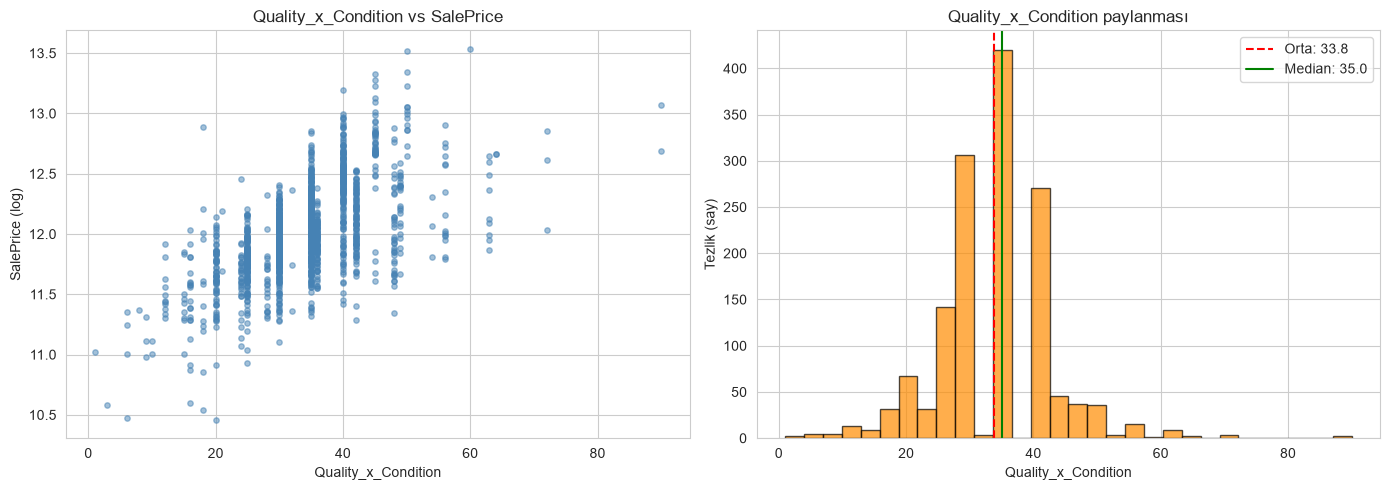

Quality_x_Condition ilə SalePrice korrelyasiyası: 0.608


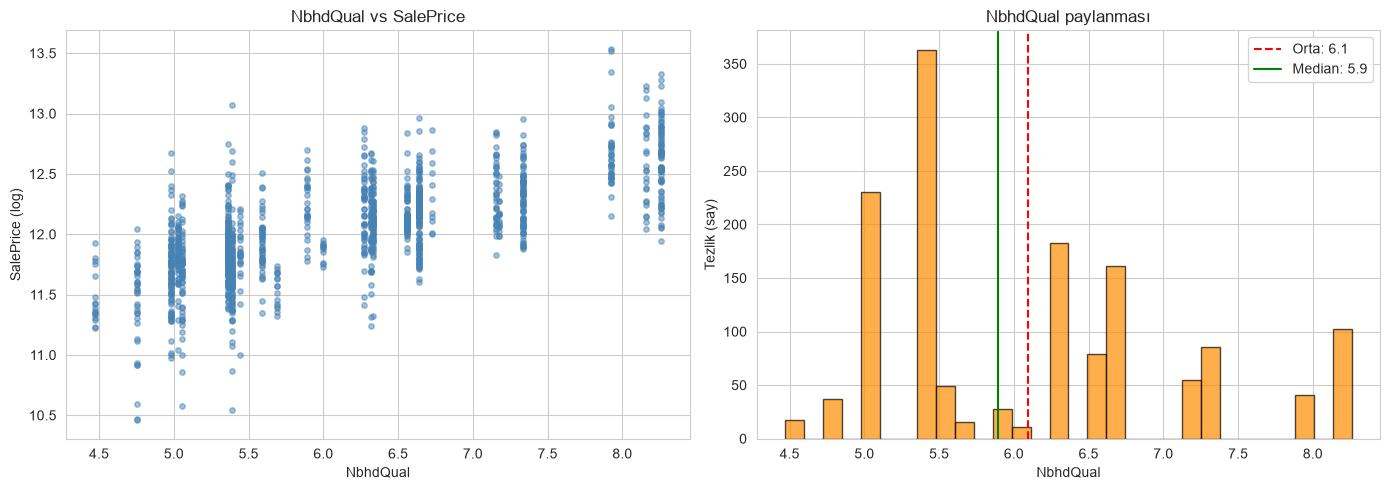

NbhdQual ilə SalePrice korrelyasiyası: 0.721


In [17]:
# TODO: Yaradılmış xüsusiyyətləri təhlil edin
# Əgər Mərhələ 3-də 'TotalSF' kimi xüsusiyyətlər yaratmısınızsa:
# - Yaradılmış xüsusiyyət ilə SalePrice arasında scatter plot yaradın
# - Yaradılmış xüsusiyyətin paylanmasını göstərən histoqram yaradın
# - Hədəflə korrelyasiyanı müqayisə edin

# Yaradılmış xüsusiyyətlərin təhlili burada
# Nümunə struktur yuxarıdakı şərhlərdə verilmişdir

fe_numeric = df_fe.select_dtypes(include=['int64' , 'float64']).columns.tolist()
new_features = [col for col in fe_numeric if col not in df_original]
print(f"Aşkar edilən yeni xüsusiyyətlər: {new_features}\n")

for feature in new_features:
    values = df_fe[feature].copy()

    fig , axes = plt.subplots(1, 2 ,figsize=(14,5))

    axes[0].scatter(values , y, alpha = 0.5 , color = 'steelblue' , s = 15)
    axes[0].set_title(f'{feature} vs SalePrice')
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel('SalePrice (log)')

    axes[1].hist(values , bins = 30 , color = 'darkorange' , edgecolor = 'black' , alpha = 0.7)
    axes[1].axvline(values.mean(), color='red', linestyle='--', label=f'Orta: {values.mean():,.1f}')
    axes[1].axvline(values.median(), color='green', linestyle='-', label=f'Median: {values.median():,.1f}')
    axes[1].set_title(f'{feature} paylanması')
    axes[1].set_xlabel(feature)
    axes[1].set_ylabel('Tezlik (say)')
    axes[1].legend()

    plt.tight_layout()      
    plt.show()

    new_corr = values.corr(y)
    print(f"{feature} ilə SalePrice korrelyasiyası: {new_corr:.3f}")

In [18]:
porch_cols = ['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']
y_s = pd.Series(y.values, index=df_original.index)

for c in porch_cols:
    print(c, round(df_original[c].corr(y_s), 3))

OpenPorchSF 0.325
EnclosedPorch -0.149
3SsnPorch 0.055
ScreenPorch 0.121


In [19]:
check_cols = ['Quality_x_Area', 'OverallQual', 'GrLivArea',
            'HouseAge', 'RemodAge', 'GarageAge', 'IsNew',
            'TotalQualScore', 'Quality_x_Condition']
check_cols = [c for c in check_cols if c in df_fe.columns]

print(df_fe[check_cols].corr().round(2))

                     Quality_x_Area  OverallQual  HouseAge  RemodAge  IsNew  \
Quality_x_Area                 1.00         0.82     -0.37     -0.42   0.32   
OverallQual                    0.82         1.00     -0.57     -0.55   0.51   
HouseAge                      -0.37        -0.57      1.00      0.59  -0.59   
RemodAge                      -0.42        -0.55      0.59      1.00  -0.54   
IsNew                          0.32         0.51     -0.59     -0.54   1.00   
TotalQualScore                 0.64         0.75     -0.57     -0.55   0.48   
Quality_x_Condition            0.59         0.72     -0.16     -0.46   0.19   

                     TotalQualScore  Quality_x_Condition  
Quality_x_Area                 0.64                 0.59  
OverallQual                    0.75                 0.72  
HouseAge                      -0.57                -0.16  
RemodAge                      -0.55                -0.46  
IsNew                          0.48                 0.19  
TotalQualScor

In [20]:
check_cols = ['GarageArea', 'GarageAge', 'GarageCars', 'HouseAge']
existing = [c for c in check_cols if c in df_fe.columns]
missing = [c for c in check_cols if c not in df_fe.columns]

print("Mövcud olanlar:", existing)
print("Mövcud olmayanlar:", missing)

print(df_fe[existing].corr().round(3))

Mövcud olanlar: ['GarageCars', 'HouseAge']
Mövcud olmayanlar: ['GarageArea', 'GarageAge']
            GarageCars  HouseAge
GarageCars       1.000    -0.538
HouseAge        -0.538     1.000


---
## Tapşırıq 9: Əsas Nəticələr və Qanunauyğunluqlar

EDA-dan əldə etdiyiniz ən vacib tapıntıları ümumiləşdirin.

### Addım 9.1: Tapıntılarınızı Sənədləşdirin

Təhlilinizə əsasən bu suallara cavab verin:

#### 1. Hədəf Dəyişən (SalePrice)
- Tipik qiymət aralığı nədir?
- Paylanma normaldır, yoxsa əyridir?
- Əhəmiyyətli kənar qiymətlər varmı?

#### 2. Ən Vacib Xüsusiyyətlər
- Hansı 5 xüsusiyyət SalePrice ilə ən güclü korrelyasiyaya malikdir?
- Əlaqələr xəttidir, yoxsa qeyri-xəttidir?

#### 3. Kateqorial Müşahidələr
- Hansı kateqorial xüsusiyyətlər ən böyük qiymət fərqlərini göstərir?
- Təəccüblü qanunauyğunluqlar varmı?

#### 4. Xüsusiyyətlər Arasındakı Əlaqələr
- Hansı xüsusiyyətlər bir-biri ilə yüksək dərəcədə korrelyasiya edir?
- Bu, multikollinearlıq problemlərinə işarə edirmi?

#### 5. Yaradılmış Xüsusiyyətlər
- Yaratdığınız xüsusiyyətlər hədəflə korrelyasiyanı yaxşılaşdırdımı?
- Hansı yaradılmış xüsusiyyətlər ən perspektivlidir?

**Müşahidələrinizi buraya yazın:**

In [21]:
# TODO: Xülasə hesabatı yaradın
# Aşağıdakı bölmələri çap edin:
# 1. VERİLƏNLƏR DƏSTİNƏ ÜMUMİ BAXIŞ
#    - Ümumi nümunə sayı, xüsusiyyətlər, say/kateqorial xüsusiyyətlərin sayı
# 2. HƏDƏF DƏYİŞƏN (SalePrice)
#    - Orta, median, aralıq, əyrilik
# 3. ƏN ÇOX KORRELYASİYA EDƏN İLK 5 XÜSUSİYYƏT
#    - Xüsusiyyətləri korrelyasiya dəyərləri ilə siyahılayın
# 4. ƏSAS MÜŞAHİDƏLƏR
#    - Təhlilə əsasən müşahidələrinizi əlavə edin
# 5. MODELLƏŞDİRMƏ ÜÇÜN TÖVSİYƏLƏR
#    - Tövsiyələrinizi əlavə edin

# Ayırıcılar və düzləndirmə ilə düzgün formatlaşdırmadan istifadə edin

print("=" * 60)
print("AMES HOUSING — EDA XÜLASƏ HESABATI")
print("=" * 60)

print("\n1. VERİLƏNLƏR DƏSTİNƏ ÜMUMİ BAXIŞ")
print("-" * 60)
print(f"Ümumi nümunə sayı       : {df_original.shape[0]}")
print(f"Ümumi xüsusiyyət sayı   : {df_original.shape[1]}")
print(f"Say xüsusiyyətləri      : {len(numerical_features)}")
print(f"Kateqorial xüsusiyyətlər: {len(categorical_features)}")


y_dollar = np.expm1(y)
print("\n2. HƏDƏF DƏYİŞƏN (SalePrice)")
print("-" * 60)
print(f"Orta (real $)   : ${y_dollar.mean():,.0f}")
print(f"Median (real $) : ${y_dollar.median():,.0f}")
print(f"Aralıq (real $) : ${y_dollar.min():,.0f} - ${y_dollar.max():,.0f}")
print(f"Əyrilik (xam)   : {stats.skew(y_dollar):.3f}  (güclü sağa əyilmə)")
print(f"Əyrilik (log)   : {stats.skew(y):.3f}  (demək olar ki, simmetrik)")

print("\n3. ƏN ÇOX KORRELYASİYA EDƏN İLK 5 XÜSUSİYYƏT")
print("-" * 60)
top5 = saleprice_corr.drop('SalePrice').head(5)
for feat, r in top5.items():
    print(f"{feat:<20}: r = {r:.3f}")



print("\n4. ƏSAS MÜŞAHİDƏLƏR")
print("-" * 60)
print("- SalePrice xam şəkildə güclü sağa əyilib; log-transform simmetrikləşdirib")
print("- OverallQual (r=0.82) və GrLivArea (r=0.73) ən güclü tək proqnozlaşdırıcılardır")
print("- GarageCars-GarageArea (r=0.89) və TotalBsmtSF-1stFlrSF (r=0.80) multikollinear cütlərdir")
print("- Street, Utilities, Condition2 demək olar ki, sabit kateqoriyalardır (>98% bir dəyər)")
print("- Mühəndislik olunmuş Quality_x_Area (r=0.84) tək komponentlərdən güclüdür")

print("\n5. MODELLƏŞDİRMƏ ÜÇÜN TÖVSİYƏLƏR")
print("-" * 60)
print("- Hədəfi log-transform olunmuş şəkildə modelə verin (artıq edilib)")
print("- Təkrar edən/sabit xüsusiyyətləri çıxarın (drop_B siyahısı)")
print("- Qeyri-xətti əlaqələr (məs. GarageCars=4-də düşmə) üçün ağac əsaslı modelləri sınayın")
print("=" * 60)

AMES HOUSING — EDA XÜLASƏ HESABATI

1. VERİLƏNLƏR DƏSTİNƏ ÜMUMİ BAXIŞ
------------------------------------------------------------
Ümumi nümunə sayı       : 1458
Ümumi xüsusiyyət sayı   : 77
Say xüsusiyyətləri      : 36
Kateqorial xüsusiyyətlər: 39

2. HƏDƏF DƏYİŞƏN (SalePrice)
------------------------------------------------------------
Orta (real $)   : $180,933
Median (real $) : $163,000
Aralıq (real $) : $34,900 - $755,000
Əyrilik (xam)   : 1.879  (güclü sağa əyilmə)
Əyrilik (log)   : 0.121  (demək olar ki, simmetrik)

3. ƏN ÇOX KORRELYASİYA EDƏN İLK 5 XÜSUSİYYƏT
------------------------------------------------------------
OverallQual         : r = 0.821
GrLivArea           : r = 0.725
GarageCars          : r = 0.681
GarageArea          : r = 0.656
TotalBsmtSF         : r = 0.648

4. ƏSAS MÜŞAHİDƏLƏR
------------------------------------------------------------
- SalePrice xam şəkildə güclü sağa əyilib; log-transform simmetrikləşdirib
- OverallQual (r=0.82) və GrLivArea (r=0.73) ən 

---
## Tapşırıq 10: Yekun Vizuallaşdırmalar

Ev qiymətlərinin hekayəsini danışan təsirli vizuallaşdırmalar yaradın.

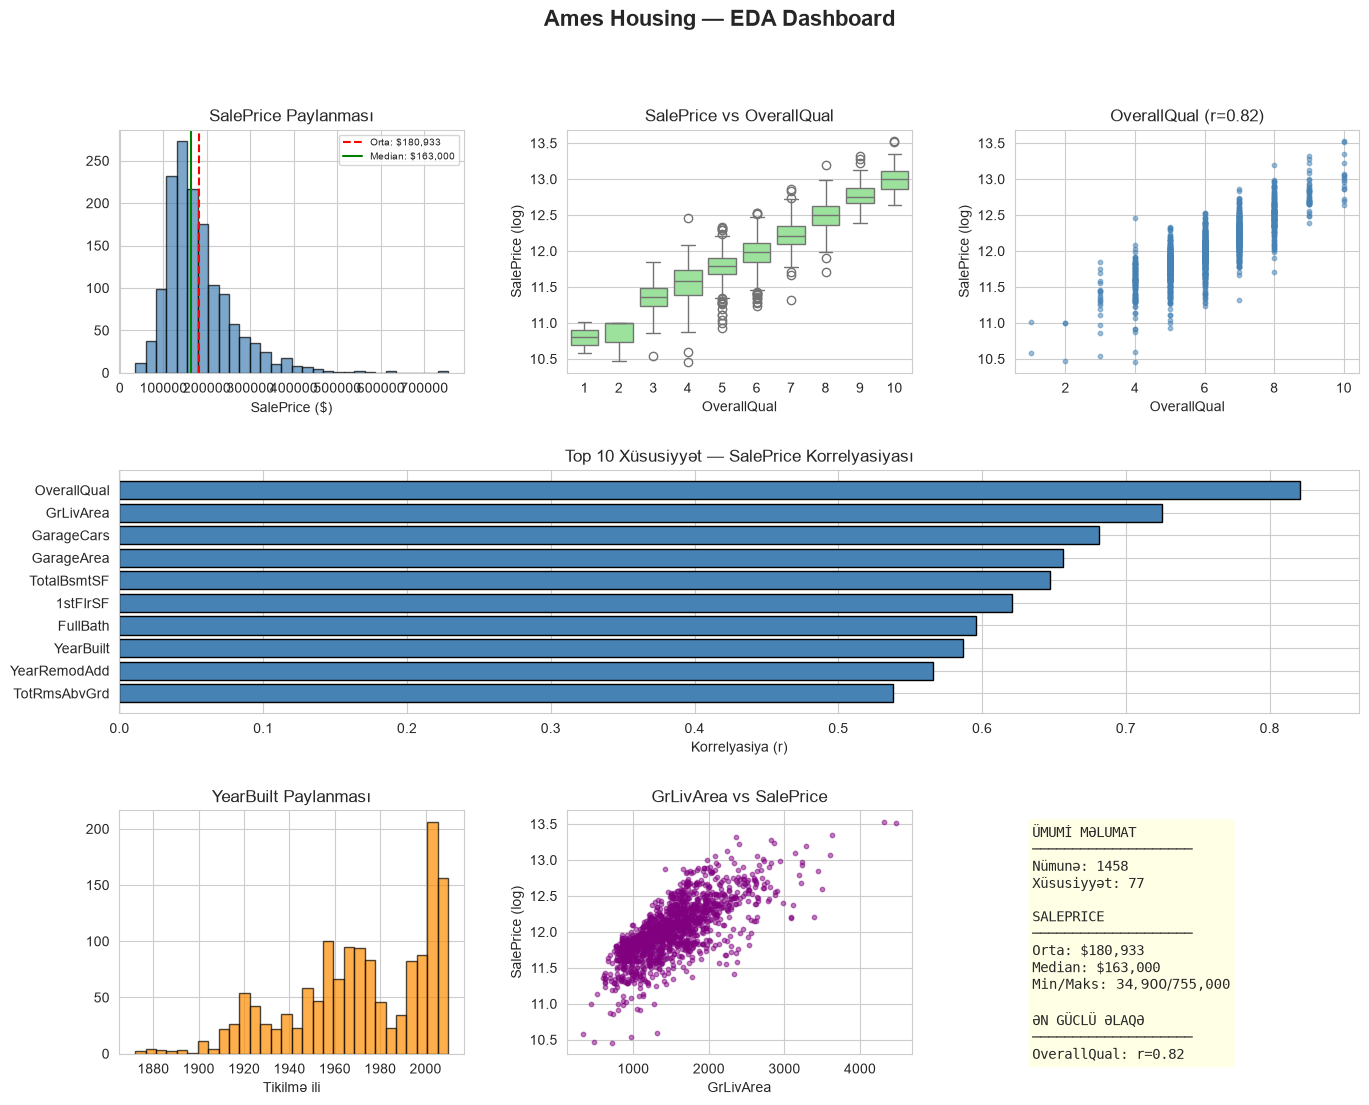

In [22]:
# TODO: Hərtərəfli dashboard tipli vizuallaşdırma yaradın
# 3x3 şəbəkə düzülüşü ilə fiqur yaradın (figsize=(16, 12))

# Panel 1: Qiymət paylanması histoqramı
# Panel 2: Ümumi Keyfiyyətə (Overall Quality) görə qiymət boxplot-u (mövcuddursa)
# Panel 3: Ən çox korrelyasiya edən xüsusiyyətin qiymətlə scatter plot-u
# Panel 4: Ən yaxşı 10 korrelyasiyanın üfüqi bar qrafiki (bütün sıranı əhatə edir)
# Panel 5: Tikilmə İli (Year Built) paylanması histoqramı
# Panel 6: Yaşayış Sahəsi (Living Area) ilə Qiymət scatter plot-u
# Panel 7: Xülasə statistikası mətn qutusu

# Dashboard üçün ümumi başlıq əlavə edin
# Düzgün məsafə və formatlaşdırmadan istifadə edin

fig = plt.figure(figsize=(16 , 12))
gs = gridspec.GridSpec(3 , 3 , figure=fig , hspace=0.4 , wspace=0.3)


# 1: Qiymət paylanması
ax1 = fig.add_subplot(gs[0,0])
ax1.hist(y_dollar , bins = 30 , color='steelblue' , edgecolor = 'black' , alpha =0.7)
ax1.axvline(y_dollar.mean(), color='red', linestyle='--', label=f'Orta: ${y_dollar.mean():,.0f}')
ax1.axvline(y_dollar.median(), color='green', label=f'Median: ${y_dollar.median():,.0f}')
ax1.set_title('SalePrice Paylanması')
ax1.set_xlabel('SalePrice ($)')
ax1.legend(fontsize=7)

# 2: OverallQual boxplot
plot_df = df_original[['OverallQual']].copy()
plot_df['SalePrice'] = y.values

ax2 = fig.add_subplot(gs[0, 1])
sns.boxplot(data=plot_df, x='OverallQual', y='SalePrice', ax=ax2, color='lightgreen')
ax2.set_title('SalePrice vs OverallQual')
ax2.set_xlabel('OverallQual')
ax2.set_ylabel('SalePrice (log)')

# 3: Ən güclü xüsusiyyətin scatter plotu 
ax3 = fig.add_subplot(gs[0, 2])
top_feat = saleprice_corr.drop('SalePrice').index[0]
ax3.scatter(df_corr[top_feat], df_corr['SalePrice'], alpha=0.5, s=10, color='steelblue')
ax3.set_title(f'{top_feat} (r={saleprice_corr[top_feat]:.2f})')
ax3.set_xlabel(top_feat)
ax3.set_ylabel('SalePrice (log)')
# 4: Top 10 korrelyasiya 
ax4 = fig.add_subplot(gs[1, :])
top10 = saleprice_corr.drop('SalePrice').head(10)
ax4.barh(top10.index[::-1], top10.values[::-1], color='steelblue', edgecolor='black')
ax4.set_title('Top 10 Xüsusiyyət — SalePrice Korrelyasiyası')
ax4.set_xlabel('Korrelyasiya (r)')
ax4.axvline(0, color='black', linewidth=0.8)

# 5: YearBuilt paylanması
ax5 = fig.add_subplot(gs[2, 0])
ax5.hist(df_original['YearBuilt'], bins=30, color='darkorange', edgecolor='black', alpha=0.7)
ax5.set_title('YearBuilt Paylanması')
ax5.set_xlabel('Tikilmə ili')

# 6: GrLivArea vs SalePrice
ax6 = fig.add_subplot(gs[2, 1])
ax6.scatter(df_original['GrLivArea'], y, alpha=0.5, s=10, color='purple')
ax6.set_title('GrLivArea vs SalePrice')
ax6.set_xlabel('GrLivArea')
ax6.set_ylabel('SalePrice (log)')

ax7 = fig.add_subplot(gs[2, 2])
ax7.axis('off')
summary_text = (
    f"ÜMUMİ MƏLUMAT\n{'─'*20}\n"
    f"Nümunə: {df_original.shape[0]}\n"
    f"Xüsusiyyət: {df_original.shape[1]}\n\n"
    f"SALEPRICE\n{'─'*20}\n"
    f"Orta: ${y_dollar.mean():,.0f}\n"
    f"Median: ${y_dollar.median():,.0f}\n"
    f"Min/Maks: ${y_dollar.min():,.0f} / ${y_dollar.max():,.0f}\n\n"
    f"ƏN GÜCLÜ ƏLAQƏ\n{'─'*20}\n"
    f"{top_feat}: r={saleprice_corr[top_feat]:.2f}"
)

ax7.text(0.05, 0.95, summary_text, transform=ax7.transAxes, fontsize=10,
        verticalalignment='top', family='monospace',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

fig.suptitle('Ames Housing — EDA Dashboard', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Xülasə və Yekun Refleksiya

### Nələr Əldə Etdiniz:

1. Hədəf dəyişənin hərtərəfli təhlilini apardınız
2. Say və kateqorial xüsusiyyətlər üzərində birdəyişənli təhlil etdiniz
3. Xüsusiyyət-hədəf əlaqələrini anlamaq üçün ikidəyişənli təhlil apardınız
4. Korrelyasiya matrisləri və pair plot-lardan istifadə edərək çoxdəyişənli təhlil etdiniz
5. Mərhələ 3-dəki yaradılmış xüsusiyyətləri qiymətləndirdiniz
6. Verilənlərdəki əsas qanunauyğunluqları və nəticələri müəyyən etdiniz
7. Peşəkar vizuallaşdırmalar yaratdınız
8. Tapıntıları və tövsiyələri sənədləşdirdiniz

### Əsas Nəticələr:

EDA təkrarlanan (iterativ) bir prosesdir və sizə aşağıdakılarda kömək edir:
- Verilənlərinizi dərindən anlamaq
- Modelləşdirmədən əvvəl potensial problemləri aşkar etmək
- Əlaqələr haqqında hipotezlər irəli sürmək
- Xüsusiyyət seçimi və mühəndisliyi barədə şüurlu qərarlar vermək
- Nəticələri maraqlı tərəflərə (stakeholders) çatdırmaq

### Yekun Refleksiya üçün Kritik Suallar:

1. Bu verilənlər dəstində ev qiymətlərinə təsir edən ən vacib 3 amil hansılardır?
2. EDA-nız gözlənilməz qanunauyğunluqlar və ya əlaqələr üzə çıxardımı?
3. Modelləşdirmədən çıxarılmalı olan xüsusiyyətlər varmı? Niyə?
4. Modelləşdirmənin uğuru üçün hansı transformasiyalar ən vacib olacaq?
5. EDA-nıza əsasən hansı modelləşdirmə yanaşmaları ən uyğun görünür?
6. Hansı əlavə xüsusiyyətlər proqnozları yaxşılaşdıra bilər?

### Növbəti Addımlar (Xətti Reqressiya Dərslərindən Sonra):

Xətti Reqressiyanı öyrəndikdən sonra siz:
1. Təmizlənmiş və ön işlənmiş verilənlərdən istifadə edərək baza modelləri (baseline models) quracaqsınız
2. Ev qiymətlərini proqnozlaşdırmaq üçün reqressiya modellərini öyrədəcəksiniz
3. Modelin performansını uyğun metriklərlə qiymətləndirəcəksiniz
4. Model nəticələrinə əsasən xüsusiyyət mühəndisliyini təkrarlayacaqsınız
5. Test verilənlər dəsti üçün proqnozlar yaradacaqsınız
6. Proqnozlarınızı Kaggle-a təqdim edəcəksiniz

### Təbrik edirik!

Siz aşağıdakıları əhatə edən hərtərəfli verilənlərin hazırlanması iş axınını tamamladınız:
- Verilənlərin Təmizlənməsi (Data Cleaning)
- Verilənlərin Ön İşlənməsi (Data Preprocessing)
- Xüsusiyyət Mühəndisliyi (Feature Engineering)
- Kəşfiyyat Verilənlər Təhlili (Exploratory Data Analysis)

Verilənləriniz artıq maşın öyrənməsi modelləşdirməsinə hazırdır. Əla iş!